Data Description

- `data_arc_en.csv` — electrode data.
- `data_bulk_en.csv` — information on bulk material additions (volume).
- `data_bulk_time_en.csv` — timestamps for bulk material additions.
- `data_gas_en.csv` — gas-purging process data.
- `data_temp_en.csv` — temperature measurement records.
- `data_wire_en.csv` — wire material data (volume).
- `data_wire_time_en.csv` — timestamps for wire material additions.

📌 In every file, the **`key`** column represents the **batch number**.

**Multiple rows may have the same `key` value**, since each can correspond to **different iterations of the steel treatment process**.

final_steel_en.zip

Files: https://coding-bootcamps.notion.site/signed/attachment%3A92df8849-9d07-4fed-8d0b-a38d9c22baf2%3Afinal_steel_en.zip?table=block&id=3b16ed1e-fc93-8054-a314-f745738a6204&spaceId=662b586e-86b7-4f44-9740-1dc06c7a67a4&name=final_steel_en.zip&cache=v2&imgBuildSrc=downloadUrlActions

## Loading the Data

In [1]:
import pandas as pd
from pathlib import Path

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor

from sklearn.model_selection import GroupKFold, cross_validate, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from matplotlib import pyplot as plt

import seaborn as sns

import numpy as np

import time

# Directory containing the datasets
# This variable makes it easier to move this notebook between my local environment and
# the bootcamp environment
data_location = Path("../../data/final_steel_en/")

random_state=12345

In [2]:
## helper function -> snake_case
# Standardize column names to snake_case
def snake_case_columns(df:pd.DataFrame):
    df.columns = (
        df.columns.str.lower()
        .str.strip()
        .str.replace("-","_")
        .str.replace(" ","_")
    )
    return df

## helper function
# Combine the datasets into a single long-format dataset
def build_long_dataset(arc, bulk_time, wire_time, temp):
    arc_long = (
        arc.drop(
            columns=[
                'active_power',
                'reactive_power',
                'arc_heating_interval'
            ]
        )
        .melt(
            id_vars=['key', 'heating_cycle_no'],
            var_name='variable',
            value_name='timestamp'
        )
    )

    bulk_long = (
        bulk_time.melt(
            id_vars='key',
            var_name='variable',
            value_name='timestamp'
        )
        .dropna(subset=['timestamp'])
    )

    wire_long = (
        wire_time.melt(
            id_vars='key',
            var_name='variable',
            value_name='timestamp'
        )
        .dropna(subset=['timestamp'])
    )

    temp_long = temp.rename(
        columns={'sampling_time': 'timestamp'}
    ).copy()

    temp_long['variable'] = 'sampling'

    temp_long = temp_long[
        ['key', 'variable', 'timestamp', 'temperature']
    ]

    return (
        pd.concat(
            [arc_long, bulk_long, wire_long, temp_long],
            ignore_index=True
        )
        .sort_values(['key', 'timestamp'], kind='stable')
        .reset_index(drop=True)
    )

In [3]:
# Electrode data
data_arc_en_raw = pd.read_csv(data_location / "data_arc_en.csv",parse_dates=["Arc heating start", 'Arc heating end'])
data_arc_en = data_arc_en_raw.copy()
data_arc_en = snake_case_columns(data_arc_en)

#
data_bulk_en_raw = pd.read_csv(data_location / "data_bulk_en.csv")
data_bulk_en = data_bulk_en_raw.copy()
data_bulk_en = snake_case_columns(data_bulk_en)

data_bulk_time_en_raw = pd.read_csv(data_location / "data_bulk_time_en.csv",parse_dates=[x for x in range(1,16,1)])
data_bulk_time_en = data_bulk_time_en_raw.copy()
data_bulk_time_en = snake_case_columns(data_bulk_time_en)

data_gas_en_raw = pd.read_csv(data_location / "data_gas_en.csv")
data_gas_en = data_gas_en_raw.copy()
data_gas_en = snake_case_columns(data_gas_en)

data_temp_en_raw = pd.read_csv(data_location / "data_temp_en.csv", parse_dates=['Sampling time'])
data_temp_en = data_temp_en_raw.copy()
data_temp_en = snake_case_columns(data_temp_en)

data_wire_en_raw = pd.read_csv(data_location / "data_wire_en.csv")
data_wire_en = data_wire_en_raw.copy()
data_wire_en = snake_case_columns(data_wire_en)

data_wire_time_en_raw = pd.read_csv(data_location / "data_wire_time_en.csv", parse_dates=[x for x in range(1,10,1)])
data_wire_time_en = data_wire_time_en_raw.copy()
data_wire_time_en = snake_case_columns(data_wire_time_en)

# Data Processing and Cleaning

To make the following analyses easier, we will create several columns and new datasets in **long** format.

In [4]:
## Column representing the duration of each heating cycle
data_arc_en['arc_heating_interval'] = (data_arc_en['arc_heating_end'] - data_arc_en['arc_heating_start']).dt.total_seconds()

# Create an identifier for each heating cycle within a secondary-refining batch.
# This lets us identify not only the batch but also the individual
# heating cycle.

data_arc_en = data_arc_en.sort_values(['key','arc_heating_start'])
data_arc_en['heating_cycle_no'] = data_arc_en.groupby('key').cumcount() + 1

In [5]:
## Create a unique identifier for each temperature measurement

data_temp_en = data_temp_en.sort_values(by=['key','sampling_time']).copy()
data_temp_en['sampling_no'] = data_temp_en.groupby('key').cumcount() + 1

In [6]:
data_long = build_long_dataset(
    data_arc_en,
    data_bulk_time_en,
    data_wire_time_en,
    data_temp_en
)

## Missing Values

### Electrode Data

In [7]:
data_arc_en.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 14876 entries, 0 to 14875
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   key                   14876 non-null  int64         
 1   arc_heating_start     14876 non-null  datetime64[ns]
 2   arc_heating_end       14876 non-null  datetime64[ns]
 3   active_power          14876 non-null  float64       
 4   reactive_power        14876 non-null  float64       
 5   arc_heating_interval  14876 non-null  float64       
 6   heating_cycle_no      14876 non-null  int64         
dtypes: datetime64[ns](2), float64(3), int64(2)
memory usage: 929.8 KB


### Bulk Material Data (Volume)

In [8]:
data_bulk_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   bulk_1   252 non-null    float64
 2   bulk_2   22 non-null     float64
 3   bulk_3   1298 non-null   float64
 4   bulk_4   1014 non-null   float64
 5   bulk_5   77 non-null     float64
 6   bulk_6   576 non-null    float64
 7   bulk_7   25 non-null     float64
 8   bulk_8   1 non-null      float64
 9   bulk_9   19 non-null     float64
 10  bulk_10  176 non-null    float64
 11  bulk_11  177 non-null    float64
 12  bulk_12  2450 non-null   float64
 13  bulk_13  18 non-null     float64
 14  bulk_14  2806 non-null   float64
 15  bulk_15  2248 non-null   float64
dtypes: float64(15), int64(1)
memory usage: 391.2 KB


In [9]:
data_bulk_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   key      3129 non-null   int64         
 1   bulk_1   252 non-null    datetime64[ns]
 2   bulk_2   22 non-null     datetime64[ns]
 3   bulk_3   1298 non-null   datetime64[ns]
 4   bulk_4   1014 non-null   datetime64[ns]
 5   bulk_5   77 non-null     datetime64[ns]
 6   bulk_6   576 non-null    datetime64[ns]
 7   bulk_7   25 non-null     datetime64[ns]
 8   bulk_8   1 non-null      datetime64[ns]
 9   bulk_9   19 non-null     datetime64[ns]
 10  bulk_10  176 non-null    datetime64[ns]
 11  bulk_11  177 non-null    datetime64[ns]
 12  bulk_12  2450 non-null   datetime64[ns]
 13  bulk_13  18 non-null     datetime64[ns]
 14  bulk_14  2806 non-null   datetime64[ns]
 15  bulk_15  2248 non-null   datetime64[ns]
dtypes: datetime64[ns](15), int64(1)
memory usage: 391.2 KB


We will check whether every material with a valid volume in the datasets also has a valid addition timestamp. In other words, we need to ensure that a timestamp exists for every material whose addition quantity is recorded (and vice versa).

We will also check whether all batches identified by the **`key`** column appear in both **`data_bulk_time_en`** and **`data_bulk_en`**.

In [10]:
print("Number of columns in the bulk material addition dataset:", data_bulk_en.shape[1])
print("Number of columns in the bulk material addition timestamp dataset:", data_bulk_time_en.shape[1])
print("Number of columns with matching missing-value patterns in the bulk material datasets:",((data_bulk_time_en.isnull() == data_bulk_en.isnull()).sum() == len(data_bulk_en)).sum())

Number of columns in the bulk material addition dataset: 16
Number of columns in the bulk material addition timestamp dataset: 16
Number of columns with matching missing-value patterns in the bulk material datasets: 16


Since the material quantity and addition timestamp data agree, there is no need to do anything about missing values in these datasets. Missing values indicate that the materials represented by those columns were not added to that secondary-refining batch.

### Temperature Data

In [11]:
data_temp_en.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 15907 entries, 0 to 15906
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            15907 non-null  int64         
 1   sampling_time  15907 non-null  datetime64[ns]
 2   temperature    13006 non-null  float64       
 3   sampling_no    15907 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 621.4 KB


In [12]:
data_temp_en['sampling_time'].describe(datetime_is_numeric=True)

count                            15907
mean     2019-07-02 09:55:01.000942848
min                2019-05-03 11:16:18
25%         2019-06-01 16:24:51.500000
50%                2019-06-30 10:31:14
75%                2019-08-03 12:07:59
max                2019-09-01 04:38:08
Name: sampling_time, dtype: object

In [13]:
missing_temp = data_temp_en.loc[data_temp_en['temperature'].isnull()]

In [14]:
missing_temp['sampling_time'].describe(datetime_is_numeric=True)

count                             2901
mean     2019-08-19 02:14:00.281282304
min                2019-08-06 03:24:43
25%                2019-08-12 12:51:11
50%                2019-08-18 23:26:16
75%                2019-08-25 15:52:51
max                2019-09-01 04:38:08
Name: sampling_time, dtype: object

It looks as though missing values are concentrated near the end of the dataset, as they begin on August 6, 2019, at 03:24:43. Let us check whether the original dataset contains any valid values from that timestamp onward or whether all subsequent values are null.

In [15]:
data_temp_en.loc[data_temp_en['sampling_time'] >= "2019-08-06 03:24:43"].info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 3639 entries, 12268 to 15906
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   key            3639 non-null   int64         
 1   sampling_time  3639 non-null   datetime64[ns]
 2   temperature    738 non-null    float64       
 3   sampling_no    3639 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(2)
memory usage: 142.1 KB


There are only 738 valid temperature measurements starting on 2019-08-06 at 03:24:43, so not all values near the end of the dataset are null. There does not appear to be a more serious problem with the dataset, but we still need to remove these missing temperatures. Since temperature is our prediction target, we cannot impute it without affecting the reliability of the final model by training it on values that may not reflect actual measurements.

In [16]:
data_temp_en = data_temp_en.dropna()

### Wire Material Addition Data

In [17]:
data_wire_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   wire_1  3055 non-null   float64
 2   wire_2  1079 non-null   float64
 3   wire_3  63 non-null     float64
 4   wire_4  14 non-null     float64
 5   wire_5  1 non-null      float64
 6   wire_6  73 non-null     float64
 7   wire_7  11 non-null     float64
 8   wire_8  19 non-null     float64
 9   wire_9  29 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 240.8 KB


In [18]:
data_wire_time_en.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   key     3081 non-null   int64         
 1   wire_1  3055 non-null   datetime64[ns]
 2   wire_2  1079 non-null   datetime64[ns]
 3   wire_3  63 non-null     datetime64[ns]
 4   wire_4  14 non-null     datetime64[ns]
 5   wire_5  1 non-null      datetime64[ns]
 6   wire_6  73 non-null     datetime64[ns]
 7   wire_7  11 non-null     datetime64[ns]
 8   wire_8  19 non-null     datetime64[ns]
 9   wire_9  29 non-null     datetime64[ns]
dtypes: datetime64[ns](9), int64(1)
memory usage: 240.8 KB


We will check whether every material with a valid quantity in the datasets also has a valid addition timestamp. In other words, we need to ensure that a timestamp exists for every material whose addition quantity is recorded (and vice versa).

We will also check whether all batches identified by the **`key`** column appear in both **`data_wire_time_en`** and **`data_wire_en`**.

In [19]:
print("Number of columns in the bulk material addition dataset:", data_wire_en.shape[1])
print("Number of columns in the bulk material addition timestamp dataset:", data_wire_time_en.shape[1])
print("Number of columns with matching missing-value patterns in the bulk material datasets:",((data_wire_time_en.isnull() == data_wire_en.isnull()).sum() == len(data_wire_en)).sum())

Number of columns in the bulk material addition dataset: 10
Number of columns in the bulk material addition timestamp dataset: 10
Number of columns with matching missing-value patterns in the bulk material datasets: 10


Since the material quantity and addition timestamp data agree, there is no need to do anything about missing values in these datasets. Missing values indicate that the materials represented by those columns were not added to that secondary-refining batch.

## Outliers

### **`reactive_power`** Column in the Electrode Data

In [20]:
data_arc_en.describe()

,key,active_power,reactive_power,arc_heating_interval,heating_cycle_no
count,14876.000000,14876.000000,14876.000000,14876.000000,14876.000000
mean,1615.220422,0.670441,0.452592,171.670946,3.093708
std,934.571502,0.408159,5.878702,98.186803,1.783121
min,1.000000,0.030002,-715.504924,11.000000,1.000000
25%,806.000000,0.395297,0.290991,107.000000,2.000000
50%,1617.000000,0.555517,0.415962,147.000000,3.000000
75%,2429.000000,0.857034,0.637371,214.000000,4.000000
max,3241.000000,3.731596,2.676388,907.000000,16.000000


In [21]:
data_arc_en.sort_values(by='reactive_power')

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0,3
5596,1216,2019-06-16 08:22:19,2019-06-16 08:22:30,0.030188,0.020806,11.0,6
2419,521,2019-05-22 17:42:57,2019-05-22 17:43:11,0.030563,0.021154,14.0,4
4914,1060,2019-06-11 04:31:57,2019-06-11 04:32:08,0.031630,0.022485,11.0,4
4633,1000,2019-06-09 01:17:44,2019-06-09 01:17:57,0.038186,0.022983,13.0,3
...,...,...,...,...,...,...,...
13760,2985,2019-08-23 19:03:07,2019-08-23 19:14:14,2.779279,2.335088,667.0,2
12424,2701,2019-08-13 06:11:16,2019-08-13 06:25:02,3.150762,2.397032,826.0,2
9361,2029,2019-07-20 20:19:38,2019-07-20 20:28:44,2.019395,2.459959,546.0,3
9226,2001,2019-07-19 20:19:15,2019-07-19 20:31:16,3.156276,2.504206,721.0,2


There appears to be only one extreme negative value in the `reactive_power` column. Negative reactive power is possible, so a negative value cannot automatically be considered invalid. However, this value is extreme compared with the others. Let us investigate this heating cycle further.

In [22]:
data_arc_en.loc[data_arc_en['key'] == 2116]

,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no
9778,2116,2019-07-24 00:29:52,2019-07-24 00:31:54,0.433266,0.306141,122.0,1
9779,2116,2019-07-24 00:35:50,2019-07-24 00:38:05,0.620265,0.408352,135.0,2
9780,2116,2019-07-24 00:44:48,2019-07-24 00:46:37,0.495782,-715.504924,109.0,3
9781,2116,2019-07-24 00:51:51,2019-07-24 00:52:58,0.299368,0.198796,67.0,4


In [23]:
data_long.loc[data_long['key']==2116]

,key,heating_cycle_no,variable,timestamp,temperature
39989,2116,1.0,arc_heating_start,2019-07-24 00:29:52,NaN
39990,2116,1.0,arc_heating_end,2019-07-24 00:31:54,NaN
39991,2116,NaN,sampling,2019-07-24 00:32:59,1579.0
39992,2116,2.0,arc_heating_start,2019-07-24 00:35:50,NaN
39993,2116,NaN,bulk_14,2019-07-24 00:35:59,NaN
39994,2116,2.0,arc_heating_end,2019-07-24 00:38:05,NaN
39995,2116,NaN,wire_1,2019-07-24 00:39:10,NaN
39996,2116,NaN,bulk_6,2019-07-24 00:39:50,NaN
39997,2116,NaN,sampling,2019-07-24 00:44:34,1574.0
39998,2116,3.0,arc_heating_start,2019-07-24 00:44:48,NaN


There are no obvious problems with this heating cycle or the rest of the secondary-refining batch corresponding to **`key`** 2116. Let us investigate the correlation between **`reactive_power`** and the other columns to determine whether imputation based on linear relationships between the variables might be appropriate.

In [24]:
print(f"Correlation between Reactive Power and Active Power:{data_arc_en['reactive_power'].corr(data_arc_en['active_power']):.2f}")
print(f"Correlation between Reactive Power and Heating Duration:{data_arc_en['reactive_power'].corr(data_arc_en['arc_heating_interval']):.2f}")
print(f"Correlation between Reactive Power and Heating Cycle Number: {data_arc_en['reactive_power'].corr(data_arc_en['heating_cycle_no']):.2f}")


Correlation between Reactive Power and Active Power:0.05
Correlation between Reactive Power and Heating Duration:0.06
Correlation between Reactive Power and Heating Cycle Number: -0.01


In [25]:
print("Ratio of absolute minimum to maximum *reactive_power*: ",np.abs(data_arc_en['reactive_power'].min()) / np.abs(data_arc_en['reactive_power'].max()))

Ratio of absolute minimum to maximum *reactive_power*:  267.3398045831754


Since there does not appear to be a linear relationship between the columns, this investigation alone does not allow us to determine reliably that the value is invalid.

Even so, the scale of the values does not seem consistent with this extreme negative observation. The minimum of -715.5 has an absolute magnitude 267.34 times the maximum value. As this value will be used to calculate the mean `reactive_power`, the resulting value would be an isolated extreme observation, particularly considering the scaling we will apply for `Ridge`.

Therefore, the most appropriate approach is to remove the heating cycle with a `reactive_power` value of -715.5.

In [26]:
data_arc_en = data_arc_en.drop(data_arc_en.loc[data_arc_en['reactive_power'] == data_arc_en['reactive_power'].min()].index)

### **`temperature`** Column in the Temperature Records

According to the **"Foseco Ferrous Foundryman's Handbook" (2000)**, steels commonly subjected to secondary refining in a ladle furnace solidify at different temperatures. The solidification temperature depends on the type of steel being produced, especially its carbon content. Nevertheless, the **"Foundryman's Handbook"** provides a reference minimum solidification temperature of $1444^oC$ for steels processed through ladle-furnace secondary refining. Lower temperatures are not expected in a ladle furnace. We could not find evidence of steel alloys undergoing ladle-furnace processing with lower solidification temperatures.

At the other extreme, values should be around $1600^oC$ according to various sources, but a temperature of $1700^oC$ is not necessarily catastrophic or impossible.

Therefore, temperatures below $1444^oC$ in our dataset warrant investigation as suspicious, but temperatures above $1600^oC$ cannot be dismissed as measurement errors based solely on an examination of the data.

In [27]:
data_temp_en['temperature'].describe()

count    13006.000000
mean      1591.840920
std         21.375851
min       1191.000000
25%       1581.000000
50%       1591.000000
75%       1601.000000
max       1705.000000
Name: temperature, dtype: float64

The minimum `temperature` is $1191^oC$ and the maximum is $1705^oC$. We need to investigate the low temperatures.

#### Low Temperatures

In [28]:
low_temps = data_temp_en.loc[data_temp_en['temperature'] <=1444].sort_values(by='temperature')
print("Number of batches with suspiciously low temperatures:", low_temps['key'].nunique())
display(low_temps)

Number of batches with suspiciously low temperatures: 6


,key,sampling_time,temperature,sampling_no
4350,867,2019-06-04 14:21:00,1191.0,1
12564,2561,2019-08-08 07:34:15,1204.0,1
5978,1214,2019-06-16 05:32:00,1208.0,1
7958,1619,2019-06-30 11:03:54,1218.0,1
10127,2052,2019-07-21 14:51:40,1227.0,1
8913,1818,2019-07-07 00:30:49,1383.0,7
8914,1818,2019-07-07 00:31:40,1383.0,8


There are only 7 temperatures at or below $1444^oC$ in our dataset. These measurements correspond to 6 secondary-refining batches. Since there are only 6 batches, we can inspect them manually to determine how to handle each measurement.

In [29]:
bad_keys = low_temps['key'].unique()

for key in bad_keys:
    print(f"\nBatch: {key}")

    batch_history = (
        data_long.loc[data_long['key'] == key]
        .sort_values('timestamp')
    )

    display(batch_history)


Batch: 867


,key,heating_cycle_no,variable,timestamp,temperature
16483,867,1.0,arc_heating_start,2019-06-04 14:17:51,NaN
16484,867,1.0,arc_heating_end,2019-06-04 14:20:06,NaN
16485,867,NaN,sampling,2019-06-04 14:21:00,1191.0
16486,867,NaN,sampling,2019-06-04 14:29:35,1575.0
16487,867,NaN,sampling,2019-06-04 14:30:29,1576.0
16488,867,NaN,wire_1,2019-06-04 14:32:56,NaN
16489,867,2.0,arc_heating_start,2019-06-04 14:33:04,NaN
16490,867,2.0,arc_heating_end,2019-06-04 14:35:39,NaN
16491,867,3.0,arc_heating_start,2019-06-04 14:36:50,NaN
16492,867,3.0,arc_heating_end,2019-06-04 14:37:49,NaN



Batch: 2561


,key,heating_cycle_no,variable,timestamp,temperature
48236,2561,1.0,arc_heating_start,2019-08-08 07:27:32,NaN
48237,2561,1.0,arc_heating_end,2019-08-08 07:30:32,NaN
48238,2561,NaN,sampling,2019-08-08 07:34:15,1204.0
48239,2561,NaN,sampling,2019-08-08 07:35:02,NaN
48240,2561,NaN,sampling,2019-08-08 07:35:38,NaN
48241,2561,2.0,arc_heating_start,2019-08-08 07:37:26,NaN
48242,2561,NaN,bulk_12,2019-08-08 07:38:24,NaN
48243,2561,NaN,bulk_14,2019-08-08 07:38:24,NaN
48244,2561,NaN,bulk_15,2019-08-08 07:38:24,NaN
48245,2561,2.0,arc_heating_end,2019-08-08 07:40:49,NaN



Batch: 1214


,key,heating_cycle_no,variable,timestamp,temperature
22828,1214,1.0,arc_heating_start,2019-06-16 05:26:17,NaN
22829,1214,1.0,arc_heating_end,2019-06-16 05:27:47,NaN
22830,1214,NaN,sampling,2019-06-16 05:32:00,1208.0
22831,1214,2.0,arc_heating_start,2019-06-16 05:43:10,NaN
22832,1214,NaN,bulk_12,2019-06-16 05:45:30,NaN
22833,1214,NaN,bulk_14,2019-06-16 05:45:30,NaN
22834,1214,NaN,bulk_15,2019-06-16 05:45:30,NaN
22835,1214,2.0,arc_heating_end,2019-06-16 05:48:39,NaN
22836,1214,NaN,sampling,2019-06-16 05:49:01,1608.0
22837,1214,NaN,wire_1,2019-06-16 05:50:12,NaN


... (2 outputs left out)


Batch: 2052


,key,heating_cycle_no,variable,timestamp,temperature
38700,2052,1.0,arc_heating_start,2019-07-21 14:48:42,NaN
38701,2052,1.0,arc_heating_end,2019-07-21 14:50:14,NaN
38702,2052,NaN,sampling,2019-07-21 14:51:40,1227.0
38703,2052,NaN,sampling,2019-07-21 14:52:21,1592.0
38704,2052,2.0,arc_heating_start,2019-07-21 14:54:06,NaN
38705,2052,NaN,bulk_12,2019-07-21 14:54:43,NaN
38706,2052,NaN,bulk_14,2019-07-21 14:54:43,NaN
38707,2052,NaN,bulk_15,2019-07-21 14:54:43,NaN
38708,2052,2.0,arc_heating_end,2019-07-21 14:58:31,NaN
38709,2052,3.0,arc_heating_start,2019-07-21 15:03:26,NaN



Batch: 1818


,key,heating_cycle_no,variable,timestamp,temperature
34149,1818,1.0,arc_heating_start,2019-07-06 23:56:28,NaN
34150,1818,1.0,arc_heating_end,2019-07-06 23:59:37,NaN
34151,1818,NaN,sampling,2019-07-07 00:00:14,1627.0
34152,1818,2.0,arc_heating_start,2019-07-07 00:01:20,NaN
34153,1818,2.0,arc_heating_end,2019-07-07 00:11:25,NaN
34154,1818,NaN,sampling,2019-07-07 00:13:02,1650.0
34155,1818,3.0,arc_heating_start,2019-07-07 00:13:13,NaN
34156,1818,3.0,arc_heating_end,2019-07-07 00:20:29,NaN
34157,1818,NaN,sampling,2019-07-07 00:25:28,1650.0
34158,1818,NaN,sampling,2019-07-07 00:26:03,1650.0


Above is the history of each batch containing at least one suspiciously low temperature. Let us examine them in the order shown:

- Batch **`key`** 867: A temperature of 1191.0 was recorded at 2019-06-04 14:21:00, but another measurement 8.5 minutes later recorded 1575.0, with no heating cycle in between.
  - The 1191.0 measurement appears to be a **measurement error** and can be discarded, since there are other valid measurements shortly afterward.
- Batch **`key`** 2561: The only valid recorded temperature is 1204.0. We cannot establish whether this was a measurement error, but there are no other valid temperatures.
  - **This entire batch contains no useful training data and should be discarded.**
- Batch **`key`** 1214: A temperature of 1208.0 was recorded shortly after a heating cycle ended. The batch proceeded through the rest of secondary refining, with material additions, additional heating cycles, and temperature measurements.
  - The 1204.0 measurement appears to be a **measurement error**, since processing continued normally after this measurement, which was below the metallurgical limits we established. Subsequent temperatures were much closer to 1600.0. Thus, we have insufficient evidence that this reading was valid. Nevertheless, we also lack information about the decisions operators made when continuing the process, or whether they judged empirically that this measurement was invalid (if such a discussion took place).
- Batch **`key`** 1619: A temperature of 1218.0 was recorded at 2019-06-30 11:03:54, but a repeat measurement less than a minute later, at 2019-06-30 11:04:39, recorded 1623.0 with no heating cycle in between.
  - The 1218 reading appears to be a **measurement error** and can be discarded, since there are valid repeat measurements shortly afterward.
- Batch **`key`** 2052: A temperature of 1227.0 was recorded at 2019-07-21 14:51:40, but another measurement approximately 0.5 minutes later, at 2019-07-21 14:52:21, recorded 1592.0, with no heating cycle in between.
  - The 1227.0 measurement appears to be a **measurement error** and can be discarded, since there are valid repeat measurements shortly afterward.
- Batch **`key`** 1818: Temperatures of 1383.0 were recorded at 2019-07-07 00:30:49 and 2019-07-07 00:31:40, but another measurement about a minute after the second suspicious reading, at 2019-07-07 00:32:55, recorded 1680.0 without an intervening heating cycle. Later measurements of 1667.0, 1667.0, and 1671.0 were also recorded, along with earlier measurements around 1650.0, 1663.0, and 1627.0. The higher readings appear valid because they are above our metallurgical threshold of 1444.0 and are more consistent, whereas the very low readings appear invalid, particularly because they fall among heating cycles with more convincing temperature measurements.
  - These two 1383.0 measurements appear to be **measurement errors** and can be discarded, since valid repeat measurements were made soon afterward.

NOTE: A future rule for automating the cleaning of a dataset like this could involve:

- Clearly defining the minimum temperature accepted as valid (we are using $1444^oC$ as a convention based on metallurgical literature, but this value should ideally be defined by Steelproof as both a metallurgical and an operational limit, since Steelproof's operational lower bound could be higher).
- Automatically removing all temperatures designated **invalid**, or removing only those **invalid** temperatures that have subsequent measurements.

In any case, because our model-training objective involves temperature, it is essential for the data to be as clean as possible. It is difficult to imagine a situation where we would retain a temperature determined to be **invalid** simply because a batch has no subsequent measurement to replace it. A rule for removing clearly invalid temperatures (below a predefined, justified minimum) seems straightforward and appropriate, provided it does not remove all merely "suspicious" observations that do not cross a threshold established as "impossible."

In [30]:
# Remove low temperatures

data_temp_en = data_temp_en.loc[
    data_temp_en['temperature'] > 1444
].copy()

#### High Temperatures

In [31]:
high_temps = data_temp_en.loc[data_temp_en['temperature'] >1650].sort_values(by='temperature')


print("Number of high-temperature measurements recorded:", len(high_temps))
print("Number of affected batches:", high_temps['key'].nunique())
print("Maximum recorded temperature:", high_temps['temperature'].max())

high_temps.describe()

Number of high-temperature measurements recorded: 171
Number of affected batches: 70
Maximum recorded temperature: 1705.0


,key,temperature,sampling_no
count,171.000000,171.000000,171.000000
mean,1099.128655,1664.807018,3.707602
std,862.446899,12.273508,2.370629
min,51.000000,1651.000000,1.000000
25%,330.000000,1654.000000,2.000000
50%,931.000000,1661.000000,3.000000
75%,1817.000000,1672.500000,5.000000
max,3112.000000,1705.000000,12.000000


We have no valid justification for excluding or modifying the high temperatures recorded. We lack sufficient information to conclude that they are errors, experimentally invalid, or the result of circumstances that should be excluded from training. Therefore, we will retain the 171 recorded temperatures above $1650^oC$.

## Duplicate Records, Data Integrity, and **`key`** Integrity

In our planning notebook, we previously found only one duplicate row in **`data_ar_enc`**, but those rows correspond to heating cycles in different batches (identified by different **`key`** values). Therefore, these records do not need to be removed. There are no duplicate records in the other datasets.

We will now proceed to check data integrity, particularly the following aspects:

- Every heating cycle must have a recorded end time after its start time; in other words, cycle duration must be positive.
- No heating cycle may have a duration of 0 seconds.
- Heating cycles within the same batch must not overlap; one cycle should not begin before another ends.
- All batches appearing in material addition data must appear in their corresponding timestamp datasets (batches in `bulk_en` must appear in `bulk_time_en`).
- There must be no negative material additions.

### Checking Heating-Cycle Timestamp Integrity

In [32]:
# Missing heating-cycle start or end times
missing_arc_times = data_arc_en.loc[
    data_arc_en[
        ['arc_heating_start', 'arc_heating_end']
    ].isna().any(axis=1)
]

# End time equal to or before the start time
invalid_arc_times = data_arc_en.loc[
    (data_arc_en['arc_heating_end']
     <= data_arc_en['arc_heating_start'])
]

print("Missing heating timestamps:", len(missing_arc_times))
print("Invalid heating timestamps:", len(invalid_arc_times))

display(missing_arc_times.head(20))
display(invalid_arc_times.head(20))

Missing heating timestamps: 0
Invalid heating timestamps: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


In [33]:
invalid_durations = data_arc_en.loc[
    data_arc_en['arc_heating_interval'].isna()
    | (data_arc_en['arc_heating_interval'] <= 0)
]

print("Invalid heating durations:", len(invalid_durations))

display(invalid_durations.head(20))

Invalid heating durations: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no


There are no heating cycles with durations of 0 seconds or negative durations (an end timestamp before the start). All heating cycles have valid values. This holds for both the original data and the derived **`arc_heating_interval`** column.

### Checking for Overlapping Heating Cycles

In [34]:
arc_sorted = (
    data_arc_en
    .dropna(subset=[
        'arc_heating_start',
        'arc_heating_end'
    ])
    .loc[
        lambda df: (
            df['arc_heating_start'] < df['arc_heating_end']
        )
    ]
    .sort_values([
        'key',
        'arc_heating_start',
        'arc_heating_end'
    ])
    .copy()
)

# Maximum observed end time
max_end = (
    arc_sorted.groupby('key')['arc_heating_end']
    .cummax()
)

# Maximum end time of previous cycles
arc_sorted['previous_max_end'] = (
    max_end.groupby(arc_sorted['key']).shift(1)
)

# Identify cycles that overlap previous cycles
overlapping_cycles = arc_sorted.loc[
    arc_sorted['arc_heating_start']
    < arc_sorted['previous_max_end']
]

print("Overlapping Heating Cycles:", len(overlapping_cycles))
print("Number of Affected Batches:", overlapping_cycles['key'].nunique())

display(overlapping_cycles)

Overlapping Heating Cycles: 0
Number of Affected Batches: 0


,key,arc_heating_start,arc_heating_end,active_power,reactive_power,arc_heating_interval,heating_cycle_no,previous_max_end


Heating cycles within the same batch do not overlap.

### Rechecking Duplicate Heating-Cycle Start and End Times

In [35]:
for col in ['arc_heating_start', 'arc_heating_end']:
    duplicates = data_arc_en.loc[
        data_arc_en.duplicated(
            subset=['key', col],
            keep=False
        )
        & data_arc_en[col].notna()
    ]

    print(f"Repeated {col} within batches:", len(duplicates))

    if not duplicates.empty:
        display(
            duplicates.sort_values(['key', col]).head(20)
        )

Repeated arc_heating_start within batches: 0
Repeated arc_heating_end within batches: 0


In [36]:
duplicate_temp_times = data_temp_en.loc[
    data_temp_en.duplicated(
        subset=['key', 'sampling_time'],
        keep=False
    )
    & data_temp_en['sampling_time'].notna()
]

print("Rows with duplicate sampling timestamps:",
      len(duplicate_temp_times))

display(
    duplicate_temp_times
    .sort_values(['key', 'sampling_time'])
    .head(20)
)

Rows with duplicate sampling timestamps: 0


,key,sampling_time,temperature,sampling_no


In [37]:
missing_temp_times = data_temp_en.loc[
    data_temp_en['sampling_time'].isna()
]

invalid_temp_values = data_temp_en.loc[
    data_temp_en['temperature'] <= 0
]

print("Missing sampling timestamps:", len(missing_temp_times))
print("Nonpositive temperatures:", len(invalid_temp_values))

display(missing_temp_times.head(20))
display(invalid_temp_values.head(20))

Missing sampling timestamps: 0
Nonpositive temperatures: 0


,key,sampling_time,temperature,sampling_no


,key,sampling_time,temperature,sampling_no


Checking Duplicate Keys in Datasets with One Row per Key

In [38]:
single_row_datasets = {
    'bulk': data_bulk_en,
    'bulk_time': data_bulk_time_en,
    'wire': data_wire_en,
    'wire_time': data_wire_time_en,
    'gas': data_gas_en
}

for name, df in single_row_datasets.items():
    duplicate_keys = df.loc[
        df['key'].duplicated(keep=False)
    ]

    print(f"{name}: {len(duplicate_keys)} rows with duplicate (key) values")

    if not duplicate_keys.empty:
        display(duplicate_keys.head(20))

bulk: 0 rows with duplicate (key) values
bulk_time: 0 rows with duplicate (key) values
wire: 0 rows with duplicate (key) values
wire_time: 0 rows with duplicate (key) values
gas: 0 rows with duplicate (key) values


We previously verified that the material quantity and addition timestamp datasets have matching data availability. That check assumes that both datasets have the same number of rows in the same order. Let us perform a more robust check to determine whether the sets of batch keys match across each pair of datasets.

In [39]:
material_pairs = [
    ('bulk', data_bulk_en, data_bulk_time_en),
    ('wire', data_wire_en, data_wire_time_en)
]

for name, quantity_df, time_df in material_pairs:
    quantity_keys = set(quantity_df['key'].dropna())
    time_keys = set(time_df['key'].dropna())

    only_quantity = quantity_keys - time_keys
    only_time = time_keys - quantity_keys

    print(f"\n{name.upper()}")
    print("Keys found only in quantities:", len(only_quantity))
    print("Keys found only in timestamps:", len(only_time))

    if only_quantity:
        print("Examples:", sorted(only_quantity)[:10])

    if only_time:
        print("Examples:", sorted(only_time)[:10])


BULK
Keys found only in quantities: 0
Keys found only in timestamps: 0

WIRE
Keys found only in quantities: 0
Keys found only in timestamps: 0


#### Checking for Material Additions of Zero

In [40]:
print("Number of Bulk Material Additions with value 0:",(data_bulk_en == 0).sum().sum())
print("Number of Wire Material Additions with value 0:",(data_wire_en == 0).sum().sum())

Number of Bulk Material Additions with value 0: 0
Number of Wire Material Additions with value 0: 0


### Additional Data Integrity Conclusions

As noted earlier, there are no negative material additions. There are also no missing values in any **`key`** column across the datasets. The only missing observations that needed to be removed were temperatures.

# Data Preparation

## Identifying Events, Defining Valid Intervals, and Aggregating Data by Temperature Measurement Interval

We want data that follow our proposed model design:

$\hat{T} = f(T_{1},X_{\mathrm{interval}})$

Here, $\hat{T}$ is the temperature predicted by the model, $T_{1}$ is the previous temperature, and $X_{\mathrm{interval}}$ represents the information we have about the process stage preceding the temperature measurement, such as:

- Timing information about temperature measurement $T_{1}$ and its temporal relationship with temperature $T_{2}$.
- Information about heating cycles that took place during this stage.
- Timing information about heating cycles during this stage.
- Information on bulk and wire material additions, including both quantities and timestamps.
- Other features derived from our data.

We will begin by creating a dataset of temperature measurement pairs for every batch. Removing pairs with invalid/missing/null values for $T_{1}$ (**`temp_1`**) will eliminate both records from batches with only one temperature reading and the first temperature reading of every batch. A batch's first measurement cannot be used as a training target because it cannot be defined as **`temp_2`** without a corresponding **`temp_1`**.

In [41]:
# Number of valid measurements per batch
temp_counts = data_temp_en.groupby("key").size()

# Sort measurements chronologically
intervals = (
    data_temp_en
    .sort_values(by=["key", "sampling_time"])
    .copy()
)

# Identify the previous measurement within each batch
g = intervals.groupby("key")

intervals["temp_1"] = g["temperature"].shift(1)
intervals["time_1"] = g["sampling_time"].shift(1)
intervals["sampling_no_1"] = g["sampling_no"].shift(1)

# Exclude rows without a previous measurement
intervals = intervals.dropna(subset=["temp_1"]).copy()

# Identify T2 and its timestamp
intervals = intervals.rename(columns={
    "temperature": "temp_2",
    "sampling_time": "time_2",
    "sampling_no": "sampling_no_2"
})

# Calculate interval duration in seconds
intervals["interval_duration"] = (
    (intervals["time_2"] - intervals["time_1"])
    .dt.total_seconds()
)

# Assign a unique identifier to each interval
intervals['interval_no'] = intervals.groupby("key").cumcount() + 1

display(intervals.head())

,key,time_2,temp_2,sampling_no_2,temp_1,time_1,sampling_no_1,interval_duration,interval_no
1,1,2019-05-03 11:25:53,1604.0,2,1571.0,2019-05-03 11:16:18,1.0,575.0,1
2,1,2019-05-03 11:29:11,1618.0,3,1604.0,2019-05-03 11:25:53,2.0,198.0,2
3,1,2019-05-03 11:30:01,1601.0,4,1618.0,2019-05-03 11:29:11,3.0,50.0,3
4,1,2019-05-03 11:30:39,1613.0,5,1601.0,2019-05-03 11:30:01,4.0,38.0,4
6,2,2019-05-03 11:38:00,1577.0,2,1581.0,2019-05-03 11:37:27,1.0,33.0,1


In [42]:
# All measurement pairs/intervals must have a positive duration
assert (intervals["interval_duration"] > 0).all()

# Every target temperature must represent a unique interval
assert not intervals.duplicated(
    subset=["key", "sampling_no_2"]
).any()

In [43]:
print("Number of intervals:", len(intervals))
print("Number of batches:", intervals["key"].nunique())

display(intervals["interval_duration"].describe())

Number of intervals: 9784
Number of batches: 2475


count     9784.000000
mean       469.070830
std        481.878022
min          3.000000
25%        196.000000
50%        384.000000
75%        643.000000
max      14663.000000
Name: interval_duration, dtype: float64

We have 9,784 intervals between successive temperature measurements. We now need to identify which intervals contain information useful for the model and exclude intervals without material additions or heating cycles between the two measurements.

We will start by joining the heating-cycle data to our temperature measurement intervals.

In [44]:
temp_pairs = (
    intervals
    .dropna(subset=['time_1', 'time_2'])
    [['key', 'time_1', 'time_2','interval_no']]
    .sort_values(['key', 'time_2'])
    .copy()
)

# Join candidate heating cycles (this dataset will include extra records)
heating_candidates = temp_pairs.merge(
    data_arc_en[
        [
            'key',
            'heating_cycle_no',
            'arc_heating_start',
            'arc_heating_end',
            'active_power',
            'reactive_power'
        ]
    ],
    on='key',
    how='inner'
)


# Select valid heating cycles (starting after time_1 and ending before time_2)
heating_mask = (
    (heating_candidates['arc_heating_start']
     >= heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end']
     <= heating_candidates['time_2'])
)


# Create the dataset of heating cycles correctly aligned with intervals
heating_events = heating_candidates.loc[
    heating_mask
].copy()

print("Number of valid heating cycles:",len(heating_events))
print("Number of intervals:", heating_events.groupby("key")['interval_no'].nunique().sum())

Number of valid heating cycles: 8636
Number of intervals: 7003


We now need to check whether any heating cycle crosses the timestamp of a temperature measurement. In other words, whether a heating cycle began before a temperature measurement but only ended afterward. If such cases exist, they were excluded when we created the **`heating_events`** dataset. We will need to decide how to handle them.

In [45]:
overlap_mask = ((heating_candidates['arc_heating_start']< heating_candidates['time_2']) & (heating_candidates['arc_heating_end'] > heating_candidates['time_1']))

partial_heating = heating_candidates.loc[overlap_mask & ~heating_mask].copy()

print("Heating cycles partially overlapping intervals:",len(partial_heating))

print("Affected intervals:",len(partial_heating[['key', 'interval_no']].drop_duplicates()))

display(partial_heating.head())

Heating cycles partially overlapping intervals: 22
Affected intervals: 22


,key,time_1,time_2,interval_no,heating_cycle_no,arc_heating_start,arc_heating_end,active_power,reactive_power
4557,186,2019-05-10 06:16:03,2019-05-10 06:19:47,1,1,2019-05-10 06:15:54,2019-05-10 06:18:01,0.398524,0.290086
5673,236,2019-05-12 04:19:28,2019-05-12 04:20:48,3,5,2019-05-12 04:20:19,2019-05-12 04:21:01,0.153360,0.095215
5678,236,2019-05-12 04:20:48,2019-05-12 04:23:58,4,5,2019-05-12 04:20:19,2019-05-12 04:21:01,0.153360,0.095215
18429,904,2019-06-05 16:16:22,2019-06-05 16:23:11,2,4,2019-06-05 16:19:38,2019-06-05 16:23:31,0.864446,0.572309
18436,904,2019-06-05 16:23:11,2019-06-05 16:23:38,3,4,2019-06-05 16:19:38,2019-06-05 16:23:31,0.864446,0.572309


In [46]:
# Heating cycles that started before T1 and ended within the interval
starts_before_t1 = (
    (heating_candidates['arc_heating_start'] < heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end'] <= heating_candidates['time_2'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_1'])
)

# Heating cycles that started within the interval and ended after T2
ends_after_t2 = (
    (heating_candidates['arc_heating_start'] >= heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_start'] < heating_candidates['time_2'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_2'])
)

# Heating cycles spanning the entire interval
spans_interval = (
    (heating_candidates['arc_heating_start'] < heating_candidates['time_1'])
    &
    (heating_candidates['arc_heating_end'] > heating_candidates['time_2'])
)

print("Starting before T1:", starts_before_t1.sum())
print("Ending after T2:", ends_after_t2.sum())
print("Spanning the entire interval:", spans_interval.sum())

Starting before T1: 11
Ending after T2: 7
Spanning the entire interval: 4


As mentioned earlier, our **`heating_events`** dataset already excludes heating cycles that overlap temperature measurements. Our investigation found 22 intervals with this problem. We could handle some of them, particularly those containing cycles that started before T1. Those cycles could be modified by moving their start time to the exact moment of the T1 measurement and adjusting their duration accordingly. However, this would also require us to remove the `active_power` and `reactive_power` values for these intervals because we cannot properly adjust them when changing the cycle duration.

Unfortunately, this would mean introducing null values for `active_power` and `reactive_power`. We would also have to assume that artificially modifying heating cycles in this way is acceptable, which we cannot establish from the available information.

On the other hand, if we retained overlapping heating cycles, including cycles extending beyond T2, we would introduce data leakage. Our data would include information about events occurring after T2 (our target), which would be incorrect.

Therefore, I decided to exclude these 22 intervals from the training data. We already have 8,637 valid heating cycles and 7,004 valid intervals. I consider excluding 22 intervals in exchange for preserving data integrity and cleanliness an appropriate choice. The exclusion already happened partially when **`heating_events`** was created, but only for the problematic **heating cycles**. We want to exclude entire **intervals** containing problematic cycles so that none of their data are retained for training.

In [47]:
# Create identifiers for intervals with overlapping data
partial_ids = pd.MultiIndex.from_frame(partial_heating[['key', 'interval_no']])

# Create identifiers for each heating event
heating_ids = pd.MultiIndex.from_frame(heating_events[['key', 'interval_no']])

# Exclude intervals associated with overlapping heating data
heating_events = heating_events.loc[~heating_ids.isin(partial_ids)].copy()

We now have two datasets:
- `intervals` -> all temperature intervals, including intervals without heating cycles and those with overlapping heating cycles.
- `heating_events` -> heating cycles assigned to temperature intervals, excluding records associated with intervals containing at least one overlapping heating cycle.

These datasets have exclusions appropriate to their respective roles. For instance, we have not excluded intervals with overlapping heating cycles from **`intervals`**. That exclusion occurred only in **`heating_events`**. When aggregating the data, we will need to respect the exclusion rules associated with each dataset. In any case, it is better to preserve the data at this stage and perform the global exclusion only once, rather than applying each exclusion rule separately to every dataset as we define them.

We also have MultiIndex identifiers for each interval within each batch, which will help us aggregate the data into the final training dataset.


We will create datasets for bulk materials and wire materials, identifying the temperature interval to which each material addition belongs.

In [48]:
## Create a long-format bulk materials dataset

data_bulk_en_long = data_bulk_en.melt(
    id_vars='key',
    var_name='bulk',
    value_name='volume_added'
)

data_bulk_time_en_long = data_bulk_time_en.melt(
    id_vars='key',
    var_name='bulk',
    value_name='timestamp'
)

# Combine material quantities and timestamps into one long-format dataset
bulk_long = data_bulk_en_long.merge(
    data_bulk_time_en_long,
    on=['key','bulk'],
    how='outer',
    validate='one_to_one'
)


# Verify that the merge worked correctly
# Expect matching missing-value patterns for volume_added and timestamp
assert (bulk_long['volume_added'].isna() == bulk_long['timestamp'].isna()).all()

In [49]:
# Join candidate heating cycles (this dataset will include extra records)
bulk_candidates = intervals[['key','interval_no','time_1','time_2']].merge(
    bulk_long,
    on='key',
    how='inner'
)

bulk_events_mask = (bulk_candidates['timestamp'] > bulk_candidates['time_1']) & (bulk_candidates['timestamp'] <= bulk_candidates['time_2'])

bulk_events = bulk_candidates.loc[bulk_events_mask]

print("Number of intervals with bulk material additions: ",bulk_events.groupby("key")['interval_no'].nunique().sum())


Number of intervals with bulk material additions:  3180


In [50]:
## Create a long-format wire materials dataset

data_wire_en_long = data_wire_en.melt(
    id_vars='key',
    var_name='wire',
    value_name='quantity_added'
)

data_wire_time_en_long = data_wire_time_en.melt(
    id_vars='key',
    var_name='wire',
    value_name='timestamp'
)

# Combine material quantities and timestamps into one long-format dataset
wire_long = data_wire_en_long.merge(
    data_wire_time_en_long,
    on=['key','wire'],
    how='outer',
    validate='one_to_one'
)


# Verify that the merge worked correctly
# Expect matching missing-value patterns for quantity_added and timestamp
assert (wire_long['quantity_added'].isna() == wire_long['timestamp'].isna()).all()

In [51]:
# Join candidate heating cycles (this dataset will include extra records)
wire_candidates = intervals[['key','interval_no','time_1','time_2']].merge(
    wire_long,
    on='key',
    how='inner'
)

wire_events_mask = (wire_candidates['timestamp'] > wire_candidates['time_1']) & (wire_candidates['timestamp'] <= wire_candidates['time_2'])

wire_events = wire_candidates.loc[wire_events_mask]

print("Number of intervals with wire material additions: ",wire_events.groupby("key")['interval_no'].nunique().sum())


Number of intervals with wire material additions:  2555


We now have four datasets:
- `intervals` -> all temperature intervals, including those without heating cycles.
- `heating_events` -> heating cycles corresponding to temperature intervals, excluding records associated with intervals containing at least one overlapping heating cycle.
- `bulk_events` -> all bulk material additions assigned to temperature intervals.
- `wire_events` -> all wire material additions assigned to temperature intervals.

We will use these datasets to describe our temperature intervals more completely. We will count the heating cycles, bulk material additions, and wire material additions within each interval.

In [52]:
idx = ['key','interval_no']

heating_counts = heating_events.groupby(idx).size()
bulk_counts = bulk_events.groupby(idx).size()
wire_counts = wire_events.groupby(idx).size()

interval_summary = intervals.set_index(idx).copy()

interval_summary['heating_count'] = heating_counts
interval_summary['bulk_count'] = bulk_counts
interval_summary['wire_count'] = wire_counts

interval_summary[
    ['heating_count', 'bulk_count', 'wire_count']
] = interval_summary[
    ['heating_count', 'bulk_count', 'wire_count']
].fillna(0).astype(int)


# Remove intervals with overlapping heating cycles
interval_summary_no_partials = interval_summary.loc[~interval_summary.index.isin(partial_ids)]

interval_summary_no_partials.info()
display(interval_summary_no_partials.head())

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 9762 entries, (1, 1) to (2499, 2)
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   time_2             9762 non-null   datetime64[ns]
 1   temp_2             9762 non-null   float64       
 2   sampling_no_2      9762 non-null   int64         
 3   temp_1             9762 non-null   float64       
 4   time_1             9762 non-null   datetime64[ns]
 5   sampling_no_1      9762 non-null   float64       
 6   interval_duration  9762 non-null   float64       
 7   heating_count      9762 non-null   int64         
 8   bulk_count         9762 non-null   int64         
 9   wire_count         9762 non-null   int64         
dtypes: datetime64[ns](2), float64(4), int64(4)
memory usage: 875.9 KB


time_2  temp_2  sampling_no_2  temp_1  \
key interval_no                                                      
1   1           2019-05-03 11:25:53  1604.0              2  1571.0   
    2           2019-05-03 11:29:11  1618.0              3  1604.0   
    3           2019-05-03 11:30:01  1601.0              4  1618.0   
    4           2019-05-03 11:30:39  1613.0              5  1601.0   
2   1           2019-05-03 11:38:00  1577.0              2  1581.0   

                             time_1  sampling_no_1  interval_duration  \
key interval_no                                                         
1   1           2019-05-03 11:16:18            1.0              575.0   
    2           2019-05-03 11:25:53            2.0              198.0   
    3           2019-05-03 11:29:11            3.0               50.0   
    4           2019-05-03 11:30:01            4.0               38.0   
2   1           2019-05-03 11:37:27            1.0               33.0   

                 heating_count  bulk_count  wire_count  
key interval_no                                         
1   1                        1           1           0  
    2                        1           0           0  
    3                        0           0           0  
    4                        0           0           0  
2   1                        0           0           0

In [53]:
no_heating_mask = interval_summary_no_partials['heating_count'] == 0
bulk_or_wire_mask = (interval_summary_no_partials['bulk_count']>0) | (interval_summary_no_partials['wire_count']>0)

no_event_mask = (interval_summary_no_partials['heating_count'] == 0) & (interval_summary_no_partials['bulk_count'] == 0) & (interval_summary_no_partials['wire_count'] ==0)


print("Number of intervals with Heating + Materials", len(interval_summary_no_partials.loc[(~no_heating_mask) & bulk_or_wire_mask]))
print("Number of intervals with Heating Only:", len(interval_summary_no_partials.loc[(~no_heating_mask) & (~bulk_or_wire_mask)]))
print("Number of intervals with Materials Only:", len(interval_summary_no_partials.loc[no_heating_mask & bulk_or_wire_mask]))
print("Number of intervals with NEITHER Heating NOR Materials:", len(interval_summary_no_partials.loc[no_event_mask]))
print()
print("Total number of intervals with training data:", len(interval_summary_no_partials.loc[(~no_heating_mask) & bulk_or_wire_mask]) + len(interval_summary_no_partials.loc[(~no_heating_mask) & (~bulk_or_wire_mask)]) + len(interval_summary_no_partials.loc[no_heating_mask & bulk_or_wire_mask]))

Number of intervals with Heating + Materials 3357
Number of intervals with Heating Only: 3646
Number of intervals with Materials Only: 364
Number of intervals with NEITHER Heating NOR Materials: 2395

Total number of intervals with training data: 7367


We have 364 intervals containing material additions but no heating cycles. I consider these intervals useful for training. The absence of a heating cycle does not mean the model cannot learn from an interval.

On the other hand, we have 2,394 intervals with neither heating cycles nor material additions. We chose to exclude these intervals from training because our initial model is intended to estimate temperature after intervals containing recorded heating or material-addition operations.

We will define the identifiers of valid intervals using **`key`** and **`interval_no`**, which form the index of **`interval_summary_no_partials`**.

In [54]:
interval_summary_eligible = interval_summary_no_partials.loc[~no_event_mask].index

## Feature Engineering and Creation of the Training Dataset

Now that our data have been prepared and selected by measurement interval, we can create the dataset used to train the models. First, we need to handle the material datasets so that each material is represented without losing its association with the corresponding interval. At the same time, we will begin feature engineering by creating a variable representing the elapsed time between a material addition and the timestamp of the temperature to be predicted: **`time_to_t2`**.

In [55]:
# Create time-related features

bulk_events.loc[:,'time_to_t2'] = (
    (bulk_events['time_2'] - bulk_events['timestamp'])
    .dt.total_seconds()
)

wire_events.loc[:,'time_to_t2'] = (
    (wire_events['time_2'] - wire_events['timestamp'])
    .dt.total_seconds()
)

/home/dan-home/miniconda3/envs/ds-tt-py39/lib/python3.9/site-packages/pandas/core/indexing.py:1597: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[key] = value
/home/dan-home/miniconda3/envs/ds-tt-py39/lib/python3.9/site-packages/pandas/core/indexing.py:1676: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)


In [56]:
idx = ['key', 'interval_no']

# Quantity of each material per interval
bulk_volumes = bulk_events.pivot(
    index=idx,
    columns='bulk',
    values='volume_added'
)

# Elapsed time between material addition and T2
bulk_times = bulk_events.pivot(
    index=idx,
    columns='bulk',
    values='time_to_t2'
).add_suffix('_time_to_t2')

# Combine bulk material features
bulk_features = pd.concat(
    [bulk_volumes, bulk_times],
    axis=1
)

bulk_features.sample(n=5,random_state=random_state)

,bulk,bulk_1,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_2,bulk_3,bulk_4,...,bulk_14_time_to_t2,bulk_15_time_to_t2,bulk_2_time_to_t2,bulk_3_time_to_t2,bulk_4_time_to_t2,bulk_5_time_to_t2,bulk_6_time_to_t2,bulk_7_time_to_t2,bulk_8_time_to_t2,bulk_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,,,,,,
3,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.0,...,NaN,NaN,NaN,NaN,231.0,NaN,NaN,NaN,NaN,NaN
943,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,124.0,...,NaN,NaN,NaN,NaN,16.0,NaN,NaN,NaN,NaN,NaN
2238,1,NaN,NaN,NaN,219.0,NaN,117.0,105.0,NaN,NaN,NaN,...,202.0,202.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1320,1,NaN,NaN,NaN,411.0,NaN,207.0,211.0,NaN,27.0,NaN,...,768.0,768.0,NaN,220.0,NaN,NaN,NaN,NaN,NaN,NaN
432,1,NaN,NaN,NaN,206.0,NaN,157.0,152.0,NaN,NaN,83.0,...,562.0,562.0,NaN,NaN,201.0,NaN,NaN,NaN,NaN,NaN


In [57]:
wire_quantities = wire_events.pivot(
    index=idx,
    columns='wire',
    values='quantity_added'
)

wire_times = wire_events.pivot(
    index=idx,
    columns='wire',
    values='time_to_t2'
).add_suffix('_time_to_t2')

wire_features = pd.concat(
    [wire_quantities, wire_times],
    axis=1
)

wire_features.sample(n=5, random_state=random_state)

,wire,wire_1,wire_2,wire_3,wire_4,wire_6,wire_7,wire_8,wire_9,wire_1_time_to_t2,wire_2_time_to_t2,wire_3_time_to_t2,wire_4_time_to_t2,wire_6_time_to_t2,wire_7_time_to_t2,wire_8_time_to_t2,wire_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,
1567,1,45.021599,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
40,1,125.230553,NaN,NaN,NaN,NaN,NaN,NaN,NaN,278.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,1,99.109917,9.114560,NaN,NaN,NaN,NaN,NaN,NaN,329.0,277.0,NaN,NaN,NaN,NaN,NaN,NaN
584,2,139.229995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1572,2,97.999199,78.174714,NaN,NaN,NaN,NaN,NaN,NaN,424.0,333.0,NaN,NaN,NaN,NaN,NaN,NaN


We will begin creating the training dataset called **`modeling_df`**.

In [58]:
# Select only valid intervals
modeling_df = (
    intervals
    .set_index(['key', 'interval_no'])
    .loc[interval_summary_eligible]
    .copy()
)

# Add the material data
modeling_df = (
    modeling_df
    .join(bulk_features, how='left')
    .join(wire_features, how='left')
)

In [59]:
# Select every possible material column (including any that may be missing)
# Without this step, the model could lack a column for a material absent from all valid intervals.
# Preserve all original material columns so the model can also handle future data with different additions.
# Column list
bulk_cols = data_bulk_en.columns.drop('key').tolist()
wire_cols = data_wire_en.columns.drop('key').tolist()


# Ensure all materials are represented by columns
quantity_cols = bulk_cols + wire_cols
time_cols = [
    f'{col}_time_to_t2' for col in quantity_cols
]

modeling_df = modeling_df.reindex(
    columns=(
        ['time_1', 'time_2']
        + quantity_cols
        + time_cols
    )
)

# No addition = quantity zero
modeling_df[quantity_cols] = (
    modeling_df[quantity_cols].fillna(0)
)

display(modeling_df.sample(n=5,random_state=random_state))

,,time_1,time_2,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,...,bulk_15_time_to_t2,wire_1_time_to_t2,wire_2_time_to_t2,wire_3_time_to_t2,wire_4_time_to_t2,wire_5_time_to_t2,wire_6_time_to_t2,wire_7_time_to_t2,wire_8_time_to_t2,wire_9_time_to_t2
key,interval_no,,,,,,,,,,,,,,,,,,,,,
2429,1,2019-08-03 13:02:39,2019-08-03 13:15:51,0.0,0.0,23.0,0.0,0.0,58.0,0.0,0.0,...,561.0,365.0,320.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1635,1,2019-06-30 21:21:36,2019-06-30 21:27:46,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,184.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1676,2,2019-07-02 04:09:31,2019-07-02 04:15:19,0.0,0.0,0.0,0.0,33.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
111,2,2019-05-07 06:14:17,2019-05-07 06:22:18,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,NaN,446.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1257,1,2019-06-17 19:41:45,2019-06-17 19:42:22,0.0,0.0,0.0,0.0,72.0,0.0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [60]:
## Verify the resulting data for errors


# Check that every interval has a unique identifier
assert modeling_df.index.is_unique

# Check that the number of rows equals the number of valid intervals
assert len(modeling_df) == len(interval_summary_eligible)

# Check that quantity columns contain no null values
assert modeling_df[quantity_cols].notna().all().all()

# Null timing values are acceptable because additions that did not occur have no timestamp.

We now have a dataset containing material addition data. We need to add the heating-cycle data.

In [61]:
# Reindex heating-cycle data for easier processing
heating_events = heating_events.set_index(["key",'interval_no']).copy()


# Create the **heating_duration** feature for each heating cycle
heating_events['heating_duration'] = (heating_events['arc_heating_end'] - heating_events['arc_heating_start']).dt.total_seconds()


# Create heating features aggregated by interval
heating_features = (
    heating_events.groupby(['key','interval_no'])
    .agg(
        heating_cycle_count=('heating_duration','size'),
        total_heating_duration=('heating_duration','sum'),
        active_power_mean=('active_power','mean'),
        reactive_power_mean=('reactive_power','mean'),
        last_heating_end=('arc_heating_end','max'),
        first_heating_start=('arc_heating_start','min')
    )
)

In [62]:
# Join heating data with the other training features

modeling_df = modeling_df.join(
    heating_features,
    how='left'
)

# Replace null values in quantitative heating columns because
# a missing value means that no heating cycles occurred. In that case,
# a value of zero helps the model learn.
modeling_df[['heating_cycle_count','total_heating_duration']] = modeling_df[['heating_cycle_count','total_heating_duration']].fillna(0)

modeling_df['heating_cycle_count'] = modeling_df['heating_cycle_count'].astype(int)


# Calculate the remaining heating-cycle timing features
# We need the time from the final heating cycle to the T2 prediction
# Also, the time from T1 to the first heating cycle
modeling_df['last_heating_to_t2'] = (modeling_df['time_2'] - modeling_df['last_heating_end']).dt.total_seconds()
modeling_df['t1_to_first_heating'] = (modeling_df['first_heating_start'] - modeling_df['time_1']).dt.total_seconds()


# Remove unused columns
modeling_df = modeling_df.drop(['last_heating_end','first_heating_start'],axis=1)

We will do the same with the temperature interval data.

In [63]:
# Reindex interval data and select only the necessary columns
temp_features = (
    intervals
    .set_index(['key','interval_no'])
    .loc[interval_summary_eligible]
    .copy()
    .loc[:,["temp_1","temp_2","interval_duration","sampling_no_1","sampling_no_2"]]
)

# Join data into **modeling_df**
modeling_df = (
    modeling_df
    .join(temp_features,how='left')
)


# Remove unused columns
modeling_df = modeling_df.drop(["sampling_no_1","sampling_no_2"],axis=1)
modeling_df = modeling_df.drop(["time_1", "time_2"],axis=1)

In [64]:
modeling_df.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 7367 entries, (1, 1) to (2499, 2)
Data columns (total 57 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   bulk_1                  7367 non-null   float64
 1   bulk_2                  7367 non-null   float64
 2   bulk_3                  7367 non-null   float64
 3   bulk_4                  7367 non-null   float64
 4   bulk_5                  7367 non-null   float64
 5   bulk_6                  7367 non-null   float64
 6   bulk_7                  7367 non-null   float64
 7   bulk_8                  7367 non-null   float64
 8   bulk_9                  7367 non-null   float64
 9   bulk_10                 7367 non-null   float64
 10  bulk_11                 7367 non-null   float64
 11  bulk_12                 7367 non-null   float64
 12  bulk_13                 7367 non-null   float64
 13  bulk_14                 7367 non-null   float64
 14  bulk_15                 7367 n

As we can see, we have a dataset with 7,369 rows and 57 columns. The columns are:

- `bulk_1` through `bulk_15` -> volume of each material added during the temperature measurement interval.
- `wire_1` through `wire_9` -> volume of each material added during the temperature measurement interval.
- `bulk_1_time_to_t2` through `bulk_15_time_to_t2` -> elapsed time between material addition and `time_2` (when the prediction is made).
- `wire_1_time_to_t2` through `wire_9_time_to_t2` -> elapsed time between material addition and `time_2` (when the prediction is made).
- `heating_cycle_count` -> number of heating cycles during the interval.
- `total_heating_duration` -> total time spent heating during the interval.
- `active_power_mean` -> mean `active_power` across all heating cycles in the interval.
- `reactive_power_mean` -> mean `reactive_power` across all heating cycles in the interval.
- `last_heating_to_t2` -> time elapsed between the end of the last heating cycle and `time_2` (when the prediction is made).
- `t1_to_first_heating` -> time elapsed between `time_1` and the start of the first heating cycle.
- `temp_1` -> temperature at `time_1`.
- `temp_2` -> temperature at `time_2`.
- `interval_duration` -> difference between `time_2` and `time_1` (the full interval duration).

# Splitting Data into Training, Validation, and Test Sets

We could use different techniques to split our data, but I believe it would be best to preserve temporal integrity so that data reserved for validation and testing come from the end of the dataset when ordered by date. It is also essential to keep entire batches together rather than splitting a batch across datasets. The best approach here is a manual split that preserves both batch grouping and chronological order.

We will reserve 20% of the data for the final model test and use the other 80% for training and validation. Since we will use scikit-learn's `GroupKFold`, we do not need a separate validation dataset. Validation will take place within the folds created by `GroupKFold`.

In [65]:
# Start timestamp for each batch
batch_start = (
    intervals.groupby('key')['time_1']
    .min()
)

# Identify batches present in modeling_df
modeling_keys = (
    modeling_df.index.get_level_values('key').unique()
)

# Sort batches chronologically
batch_order = (
    batch_start.loc[modeling_keys]
    .sort_values()
    .index
)

In [66]:
# Number of batches
n_batches = len(batch_order)

# Split boundaries
train_end = int(n_batches * 0.80)

# Select batch identifiers by time period
train_keys = batch_order[:train_end]
test_keys = batch_order[train_end:]

In [67]:
# Chronological split by batch
train_df = modeling_df.loc[
    modeling_df.index.get_level_values('key').isin(train_keys)
].copy()

test_df = modeling_df.loc[
    modeling_df.index.get_level_values('key').isin(test_keys)
].copy()

In [68]:
# Separate features and target

features_train = train_df.drop('temp_2',axis=1)
target_train = train_df['temp_2']

features_test = test_df.drop('temp_2',axis=1)
target_test = test_df['temp_2']

In [69]:
# Summarize batch and interval counts for each dataset

split_summary = pd.DataFrame({
    'dataset': ['Train', 'Test'],
    'n_batches': [
        len(train_keys),
        len(test_keys)
    ],
    'n_intervals': [
        len(train_df),
        len(test_df)
    ]
})

display(split_summary)

,dataset,n_batches,n_intervals
0,Train,1974,5940
1,Test,494,1427


In [70]:
batch_end = intervals.groupby('key')['time_2'].max()

train_last_event = batch_end.loc[train_keys].max()
test_first_event = batch_start.loc[test_keys].min()

print("Last training event:", train_last_event)
print("First test event:", test_first_event)

print(
    "Separação temporal:",
    train_last_event < test_first_event
)

Last training event: 2019-07-19 13:29:07
First test event: 2019-07-19 14:13:25
Separação temporal: True


# Preparing Data for Model Training

We do not need to preprocess the data manually for the models we will use. Instead, we will define each model within a scikit-learn Pipeline and apply scaling and imputation only for models that require them.

## Persistence Model ($T_{2} = T_{1}$)

In [71]:
# Include BaseEstimator and RegressorMixin for compatibility with other scikit-learn functions.
# Without them, calls such as cross_validate() may fail.

class t2_t1_dummy_model(BaseEstimator,RegressorMixin):
    """Prevê T2 usando T1"""
    def fit(self,X,y=None):
        return self
    def predict(self, X):
        return X['temp_1'].to_numpy()

In [72]:
model_persistence = t2_t1_dummy_model()

## Dummy Model ($T_{2} = \mathrm{mean}$)

In [73]:
model_dummy = DummyRegressor(strategy='mean')

## Ridge

Ridge requires scaling and imputation because it cannot accept null values. We will apply scikit-learn's `SimpleImputer()` and `StandardScaler()`.

In [74]:
model_ridge = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('scaler', StandardScaler()),
    ('model', Ridge())
])

## RandomForestRegressor

We are using scikit-learn version 0.24.1. In this version, `RandomForestRegressor` cannot accept null values and requires imputation. We will apply scikit-learn's `SimpleImputer()`.

In [75]:
model_random_forest = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('model', RandomForestRegressor(
        n_estimators=200,
        random_state=random_state,
        n_jobs=-1
    ))
])

## LightGBM

In [76]:
model_lightgbm = Pipeline([
    ('model', LGBMRegressor(
        n_estimators=200,
        random_state=random_state,
        verbosity=-1,
        n_jobs=-1
    ))
])

## CatBoost

In [77]:
model_catboost = Pipeline([
    ('model', CatBoostRegressor(
        iterations=300,
        loss_function='RMSE',
        random_seed=random_state,
        verbose=False,
        allow_writing_files=False,
        thread_count=-1
    ))
])

# Model Training Utilities

In [78]:
# Scoring metrics used in cross-validation
SCORING = {
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
    'R2': 'r2'
}

# 5 folds
cv = GroupKFold(n_splits=5)

# GroupKFold uses secondary-refining batch IDs as groups
groups_train = features_train.index.get_level_values('key')

In [79]:
## Standardize cross-validation for all models

def evaluate_cv(name, model, X, y, groups, cv):

    print(f"\nStarting cross-validation: {name}", flush=True)

    start_time = time.perf_counter()

    scores = cross_validate(
        estimator=model,
        X=X,
        y=y,
        groups=groups,
        cv=cv,
        scoring=SCORING,
        n_jobs=1,
        error_score='raise',
        verbose=2
    )

    elapsed_time = time.perf_counter() - start_time

    result = {
        'model': name,
        'MAE': -scores['test_MAE'].mean(),
        'MAE_std': scores['test_MAE'].std(),
        'RMSE': -scores['test_RMSE'].mean(),
        'RMSE_std': scores['test_RMSE'].std(),
        'R2': scores['test_R2'].mean(),
        'fit_time': scores['fit_time'].sum(),
        'total_time': elapsed_time
    }

    print(f"\nCompleted: {name}")
    print(f"MAE: {result['MAE']:.3f} °C")
    print(f"RMSE: {result['RMSE']:.3f} °C")
    print(f"R²: {result['R2']:.4f}")
    print(f"Total time: {elapsed_time:.1f} seconds", flush=True)


    return result

In [80]:
# Standardize calculation of each model's KPIs
# Iem measures improvement relative to the Persistence baseline

def return_kpi(y_true, y_pred,y_pred_baseline):

    baseline_mae = mean_absolute_error(y_true,y_pred_baseline)
    model_mae = mean_absolute_error(y_true, y_pred)
    model_rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    model_r2_score = r2_score(y_true, y_pred)

    return {
        'MAE': model_mae,
        'RMSE': model_rmse,
        'R2': model_r2_score,
        'Iem': (baseline_mae - model_mae)/baseline_mae
    }

In [81]:
# Create a standardized DataFrame for evaluating results
# Useful for generating plots

def build_diagnostics(X, y, predictions):

    df = pd.DataFrame({
        'actual': y.to_numpy(),
        'predicted': np.asarray(predictions),
        'persistence': X['temp_1'].to_numpy(),
        'temp_1': X['temp_1'].to_numpy(),
        'interval_minutes': X['interval_duration'].to_numpy() / 60,
        'heating_cycle_count': X['heating_cycle_count'].to_numpy()
    }, index=X.index)

    df['residual'] = df['actual'] - df['predicted']
    df['absolute_error'] = df['residual'].abs()

    df['persistence_absolute_error'] = (
        df['actual'] - df['persistence']
    ).abs()

    df['interval_type'] = np.where(
        df['heating_cycle_count'] > 0,
        'With heating',
        'Materials only'
    )

    return df

In [82]:
## Standardize the diagnostic plots using primarily the results
# from the build_diagnostics function

def plot_model_diagnostics(df, title):

    fig, axes = plt.subplots(
        nrows=2,
        ncols=2,
        figsize=(14, 11)
    )

    # 1. Actual vs. predicted temperature
    ax = axes[0, 0]

    sns.scatterplot(
        data=df,
        x='actual',
        y='predicted',
        alpha=0.3,
        s=18,
        ax=ax
    )

    min_temp = df[['actual', 'predicted']].min().min()
    max_temp = df[['actual', 'predicted']].max().max()

    ax.plot(
        [min_temp, max_temp],
        [min_temp, max_temp],
        'r--',
        label='Perfect prediction'
    )

    ax.set(
        title='Actual vs. Predicted Temperature',
        xlabel='Actual Temperature (°C)',
        ylabel='Predicted Temperature (°C)'
    )
    ax.set_xlim(min_temp, max_temp)
    ax.set_ylim(min_temp, max_temp)
    ax.set_aspect('equal', adjustable='box')
    ax.legend()

    # 2. Residual distribution
    ax = axes[0, 1]

    sns.histplot(
        data=df,
        x='residual',
        bins=40,
        kde=True,
        ax=ax
    )

    ax.axvline(0, color='red', linestyle='--')

    ax.set(
        title='Residual Distribution',
        xlabel='Residual (°C)',
        ylabel='Frequency'
    )

    # 3. Residuals vs. predicted temperature
    ax = axes[1, 0]

    sns.scatterplot(
        data=df,
        x='predicted',
        y='residual',
        alpha=0.3,
        s=18,
        ax=ax
    )

    ax.axhline(0, color='red', linestyle='--')

    ax.set(
        title='Residuals vs. Predicted Temperature',
        xlabel='Predicted Temperature (°C)',
        ylabel='Residual (°C)'
    )

    # 4. Absolute error vs. interval duration
    ax = axes[1, 1]

    sns.scatterplot(
        data=df,
        x='interval_minutes',
        y='absolute_error',
        alpha=0.3,
        s=18,
        ax=ax
    )

    ax.set(
        title='Absolute Error vs. Interval Duration',
        xlabel='Interval Duration (min)',
        ylabel='Absolute Error (°C)'
    )

    fig.suptitle(title, fontsize=16)
    fig.tight_layout()

    plt.show()

# Creating the Models

In [83]:
models = {
    'Persistence': model_persistence,
    'Dummy': model_dummy,
    'Ridge': model_ridge,
    'RandomForest': model_random_forest,
    'LightGBM': model_lightgbm,
    'CatBoost': model_catboost
}

# Training the Models

## Initial Smoke Test

In [84]:
# Use only one fold to smoke-test the models
train_indices, val_indices = next(
    cv.split(features_train, target_train, groups=groups_train)
)

smoke_results = []

for name, model in models.items():

    fitted_model = clone(model)

    fitted_model.fit(
        features_train.iloc[train_indices],
        target_train.iloc[train_indices]
    )

    predictions = fitted_model.predict(
        features_train.iloc[val_indices]
    )

    metrics = return_kpi(
        target_train.iloc[val_indices],
        predictions,
        model_persistence.predict(features_train.iloc[val_indices])
    )

    smoke_results.append({
        'model': name,
        **metrics
    })

smoke_df = pd.DataFrame(smoke_results).sort_values('MAE')

display(smoke_df)

,model,MAE,RMSE,R2,Iem
5,CatBoost,4.116900,6.111574,0.889508,0.546217
4,LightGBM,4.321901,6.244683,0.884642,0.523620
2,Ridge,4.322021,6.368515,0.880022,0.523607
3,RandomForest,4.445076,6.491567,0.875340,0.510044
0,Persistence,9.072391,12.667929,0.525280,0.000000
1,Dummy,12.146011,18.399866,-0.001511,-0.338788


Even this simple smoke test reveals a substantial difference between the models' performance, although the trained models do not appear to differ greatly from one another. Dummy and Persistence fall behind, as expected. We will train the models with cross-validation and hyperparameter search, then conduct a more detailed analysis.

## Initial Cross-Validation Without Hyperparameter Search

In [85]:
cv_results:list = []

for name, model in models.items():

    result = evaluate_cv(
        name,
        model,
        features_train,
        target_train,
        groups_train,
        cv
    )

    cv_results.append(result)

# Results
cv_df:pd.DataFrame = (
    pd.DataFrame(cv_results)
    .sort_values('MAE')
)

# Calculate baseline MAE from the Persistence model
baseline_cv_mae = cv_df.loc[
    cv_df['model'] == 'Persistence', 'MAE'
].iloc[0]

# Calculate each model's Iem relative to the baseline
cv_df['Iem'] = (
    (baseline_cv_mae - cv_df['MAE'])
    / baseline_cv_mae
)

display(cv_df)


Starting cross-validation: Persistence
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s

Completed: Persistence
MAE: 8.959 °C
RMSE: 12.376 °C
R²: 0.4637
Total time: 0.0 seconds

Starting cross-validation: Dummy
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s
[CV] END .................................................... total time=   0.0s

Completed: Dummy
MAE: 11.7

[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished
[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.2s finished


[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s
[CV] END .................................................... total time=   0.8s

Completed: RandomForest
MAE: 4.465 °C
RMSE: 6.489 °C
R²: 0.8516
Total time: 4.0 seconds

Starting cross-validation: LightGBM
[CV] END .................................................... total time=   0.2s


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    4.0s finished


[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s
[CV] END .................................................... total time=   0.2s

Completed: LightGBM
MAE: 4.250 °C
RMSE: 6.104 °C
R²: 0.8691
Total time: 0.9 seconds

Starting cross-validation: CatBoost


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.9s finished


[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.3s
[CV] END .................................................... total time=   0.4s

Completed: CatBoost
MAE: 4.083 °C
RMSE: 5.906 °C
R²: 0.8774
Total time: 1.7 seconds


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    1.7s finished


,model,MAE,MAE_std,RMSE,RMSE_std,R2,fit_time,total_time,Iem
5,CatBoost,4.082938,0.112600,5.905916,0.274050,0.877427,1.724887,1.741986,0.544269
4,LightGBM,4.250035,0.119065,6.104288,0.274616,0.869133,0.872896,0.899196,0.525618
2,Ridge,4.302148,0.161989,6.469507,0.958019,0.848245,0.112003,0.165718,0.519801
3,RandomForest,4.465061,0.143214,6.489067,0.324653,0.851592,3.663442,4.031414,0.501617
0,Persistence,8.959091,0.150597,12.376239,0.378176,0.463691,0.004837,0.014622,0.000000
1,Dummy,11.793673,0.432264,16.966318,0.886475,-0.000902,0.004463,0.012153,-0.316392


In [86]:
for row in cv_df.itertuples(index=False):
    print(f"Total training time for {row.model}: {row.fit_time:.3f}s")

Total training time for CatBoost: 1.725s
Total training time for LightGBM: 0.873s
Total training time for Ridge: 0.112s
Total training time for RandomForest: 3.663s
Total training time for Persistence: 0.005s
Total training time for Dummy: 0.004s


Before hyperparameter optimization, CatBoost was the best-performing model, with a good balance of predictive performance and resource use. It achieved an MAE of 4.08°C and an RMSE of 5.91°C, well below our previously defined thresholds of 10°C MAE and 15°C RMSE. The improvement over the baseline was also considerable: we set a minimum improvement threshold of 20%, but CatBoost achieved 54.4% before hyperparameter tuning.

LightGBM, another boosting implementation, also performed well, with an MAE of 4.25°C and an RMSE of 6.10°C. However, it took 18.07 seconds to train even without hyperparameter optimization, whereas CatBoost took only 0.08 seconds (these results may differ on other machines and apply only to the recorded runs in this notebook).

Ridge and RandomForest also produced promising results, with an MAE of 4.30°C for Ridge and 4.47°C for RandomForest. Ridge's performance does not necessarily prove that the dataset contains linear relationships, but it demonstrates how a linear model can achieve adequate predictive performance using many variables. Ridge was chosen because it uses regularization and tends to remain stable even when predictors are highly correlated.

It will be interesting to see whether these models can be improved and to compare their performance after hyperparameter optimization. I believe another important difference may be the occurrence of very large absolute errors. For instance, if a model performs well overall but has an unacceptable RMSE or many unacceptably large errors, that could be a reason to reconsider its selection.

It will also be interesting to understand how these errors compare between gradient-boosting models and a linear model such as Ridge.

## Hyperparameter Search

In [87]:
param_spaces = {

    'Ridge': {
        'model__alpha': np.logspace(-2, 3, 15)
    },

    'RandomForest': {
        'model__n_estimators': [100, 200, 400],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_leaf': [1, 2, 5],
        'model__max_features': ['sqrt', 0.7, 1.0]
    },

    'LightGBM': {
        'model__n_estimators': [100, 300, 500],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__num_leaves': [15, 31, 63],
        'model__min_child_samples': [10, 20, 40]
    },

    'CatBoost': {
        'model__iterations': [300, 600, 900],
        'model__depth': [4, 6, 8],
        'model__learning_rate': [0.02, 0.05, 0.1],
        'model__l2_leaf_reg': [1, 3, 7]
    }
}

In [88]:
searches = {}
tuning_results = []

for name, params in param_spaces.items():

    print(f"\n{'='*60}", flush=True)
    print(f"Starting optimization: {name}", flush=True)
    print(f"Combinations: 12 | Folds: {cv.n_splits}", flush=True)

    start_time = time.perf_counter()

    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=params,
        n_iter=12,
        scoring=SCORING,
        refit='MAE',
        cv=cv,
        random_state=random_state,
        n_jobs=1,
        error_score='raise',
        verbose=2
    )

    search.fit(
        features_train,
        target_train,
        groups=groups_train
    )

    elapsed_time = time.perf_counter() - start_time

    searches[name] = search

    best_idx = search.best_index_

    tuning_results.append({
        'model': name,
        'MAE': -search.cv_results_['mean_test_MAE'][best_idx],
        'MAE_std': search.cv_results_['std_test_MAE'][best_idx],
        'RMSE': -search.cv_results_['mean_test_RMSE'][best_idx],
        'RMSE_std': search.cv_results_['std_test_RMSE'][best_idx],
        'R2': search.cv_results_['mean_test_R2'][best_idx],
        'best_params': search.best_params_
    })

    print(f"\nOptimization completed: {name}")
    print(f"Best MAE: {-search.best_score_:.3f} °C")
    print(f"Best parameters: {search.best_params_}")
    print(f"Total time: {elapsed_time:.1f} seconds", flush=True)

tuning_df = (pd.DataFrame(tuning_results))

tuning_df['Iem'] = (
    (baseline_cv_mae - tuning_df['MAE'])
    / baseline_cv_mae
)

tuning_df = tuning_df.sort_values('MAE')

display(tuning_df)


Starting optimization: Ridge
Combinations: 12 | Folds: 5
Fitting 5 folds for each of 12 candidates, totalling 60 fits
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END ..................................model__alpha=0.01; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END .....................model__alpha=84.83428982440725; total time=   0.0s
[CV] END ....................model__alpha=3.1622776601683795; total tim

,model,MAE,MAE_std,RMSE,RMSE_std,R2,best_params,Iem
3,CatBoost,4.041943,0.089162,5.823822,0.260673,0.880884,"{'model__learning_rate': 0.05, 'model__l2_leaf...",0.548844
2,LightGBM,4.182862,0.113975,6.092114,0.299977,0.869899,"{'model__num_leaves': 15, 'model__n_estimators...",0.533115
0,Ridge,4.295112,0.152608,6.379005,0.808567,0.853663,{'model__alpha': 16.378937069540648},0.520586
1,RandomForest,4.415963,0.138586,6.418551,0.294342,0.855075,"{'model__n_estimators': 200, 'model__min_sampl...",0.507097


## Comparing Model Performance Before and After Hyperparameter Search

In [89]:
comparison_df = pd.concat([
    cv_df.assign(stage='Initial'),
    tuning_df.assign(stage='Tuned')
], ignore_index=True)

display(
    comparison_df[
        ['model', 'stage', 'MAE', 'RMSE', 'R2', 'Iem']
    ].sort_values(['model', 'stage'])
)

,model,stage,MAE,RMSE,R2,Iem
0,CatBoost,Initial,4.082938,5.905916,0.877427,0.544269
6,CatBoost,Tuned,4.041943,5.823822,0.880884,0.548844
5,Dummy,Initial,11.793673,16.966318,-0.000902,-0.316392
1,LightGBM,Initial,4.250035,6.104288,0.869133,0.525618
7,LightGBM,Tuned,4.182862,6.092114,0.869899,0.533115
4,Persistence,Initial,8.959091,12.376239,0.463691,0.000000
3,RandomForest,Initial,4.465061,6.489067,0.851592,0.501617
9,RandomForest,Tuned,4.415963,6.418551,0.855075,0.507097
2,Ridge,Initial,4.302148,6.469507,0.848245,0.519801
8,Ridge,Tuned,4.295112,6.379005,0.853663,0.520586


In [ ]:
# Save model results
comparison_df.to_csv('../../results/comparison_df.csv',index=False)

The models did not improve substantially after hyperparameter optimization. CatBoost's MAE improved from 4.08°C to 4.04°C, and its RMSE from 5.91°C to 5.82°C. The hyperparameter search was relatively inexpensive because this model does not take long to train, but tuning does not appear to have had a major impact on this problem.

The competitive performance of Ridge regression suggests that a substantial portion of the predictive relationships can be represented by a regularized linear model. Nevertheless, gradient-boosting models achieved better results, indicating that more flexible approaches can also benefit this problem.

The simple Ridge model achieved an MAE of approximately 4.30 both before and after tuning and an RMSE of 6.38 after tuning. This shows that this relatively inexpensive model can perform very well on business problems with many variables that are strongly linearly related to one another. CatBoost remains the better choice overall, but Ridge would not be an unreasonable option.

RandomForest also performed adequately after tuning, with an MAE of 4.42 and an RMSE of 6.42, but did not stand out. LightGBM improved to an MAE of 4.18°C and an RMSE of 6.10°C, but it takes much longer to train and tune.

The best model identified after optimization was CatBoost.

### Performance of the Best Model on Training Data

In [91]:
# Select the best model
best_model = searches['CatBoost'].best_estimator_

In [92]:
# Generate cross-validated predictions for the best model

best_model_cv_predictions = cross_val_predict(
    estimator = best_model,
    X=features_train,
    y=target_train,
    groups=groups_train,
    cv=cv,
    n_jobs=1
)

In [93]:

# Build diagnostics for the best model with our function
cv_diagnostics = build_diagnostics(
    features_train,
    target_train,
    best_model_cv_predictions
)

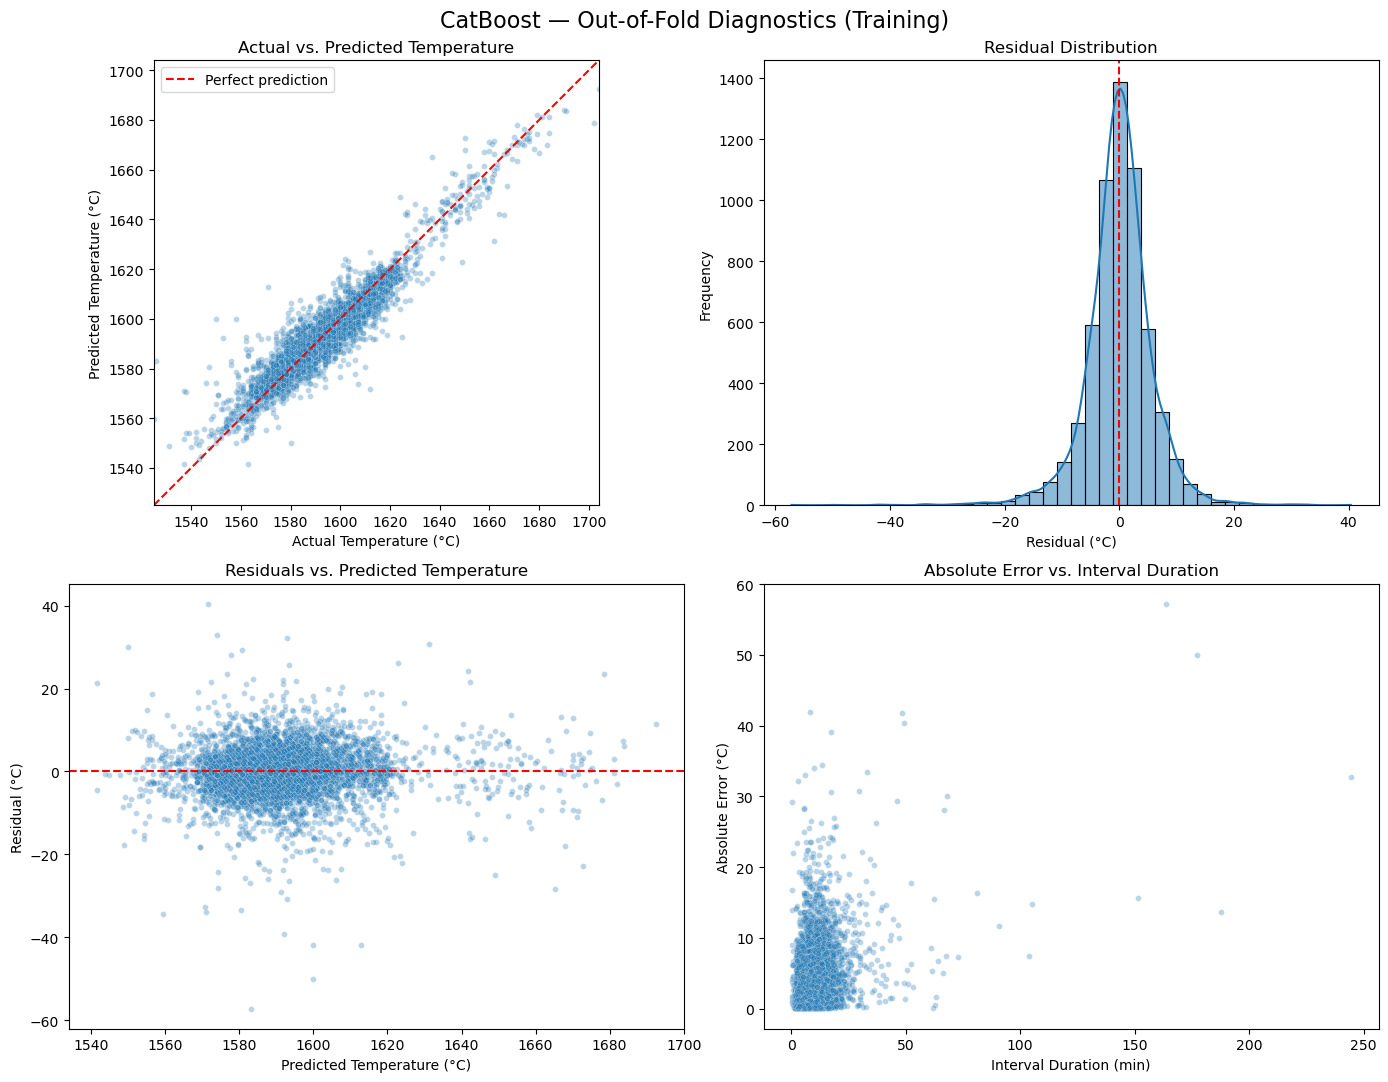

In [94]:
plot_model_diagnostics(
    cv_diagnostics,
    'CatBoost — Out-of-Fold Diagnostics (Training)'
)

As we can see, CatBoost performs well for our problem. The Actual vs. Predicted Temperatures plot shows that the vast majority of predictions fall within the expected range and are suitable for our proposed application as a reference virtual sensor. We cannot draw conclusions about real-world use without understanding how temperature relates to operational decisions for each secondary-refining batch, which would require more information and data than we have. The model could be expanded using currently unused data and additional context about the existing variables. For example, if we had timestamps for gas purging and units of measurement for `active_power` and `reactive_power`, we could use gas-purging records and engineer those power variables differently. Although this would not guarantee a better model, such information could allow us to create features that better represent the process and potentially improve predictive performance. Therefore, I cannot claim that the model's performance is operationally adequate without knowing the temperature tolerances for each process. Nevertheless, I consider the results satisfactory for an initial experimental version of a virtual sensor, especially given the limitations of the available data.

We must also consider the Absolute Error vs. Interval Duration plot. It suggests the possibility of larger errors over longer intervals. However, because most interval durations are under 30 minutes, we have fewer observations of long intervals, which limits our ability to evaluate performance under those conditions.

The residual distribution is concentrated near 0°C, with relatively little dispersion. This indicates that the model generally produces predictions close to the observed temperatures, although some observations still have large errors.

This does not mean that the model is perfect or cannot be improved. Rather, it indicates that our training process was effective within the limitations of the datasets used.

In [95]:
absolute_errors = cv_diagnostics['absolute_error']

for threshold in [5, 10, 18, 20]:
    percentage = (absolute_errors <= threshold).mean() * 100
    print(f"Errors within {threshold}°C: {percentage:.2f}%")

Errors within 5°C: 72.34%
Errors within 10°C: 92.58%
Errors within 18°C: 98.62%
Errors within 20°C: 99.04%


Here we can see that 98.62% of errors were within 18°C, 99.04% were within 20°C, and 92.58% were within 10°C. These results support our conclusion that the model performs very well, but important limitations still need to be evaluated in an operational setting before deploying it for real-world use.

## Comparing Intervals With and Without Heating Cycles

In [96]:
error_by_type = (
    cv_diagnostics
    .groupby('interval_type')['absolute_error']
    .agg(
        count='count',
        MAE='mean',
        median_absolute_error='median'
    )
)

display(error_by_type)

,count,MAE,median_absolute_error
interval_type,,,
Materials only,297,5.492954,4.055465
With heating,5643,3.965574,2.772253


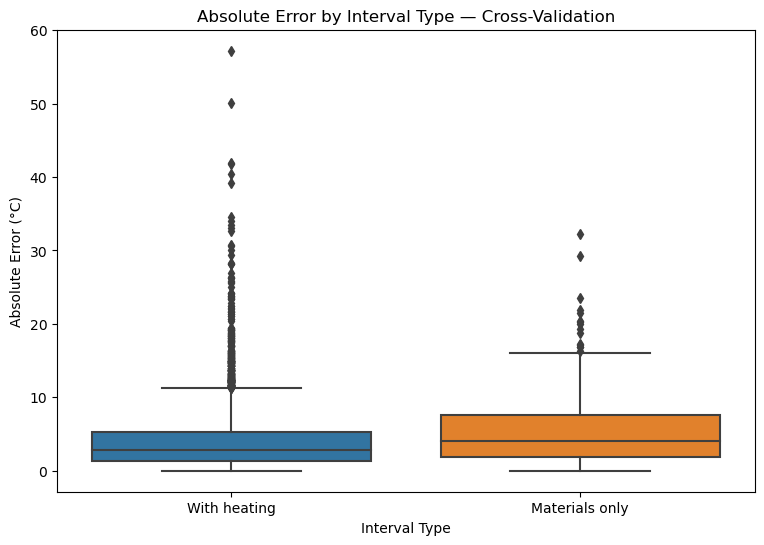

In [97]:
fig, ax = plt.subplots(figsize=(9, 6))

sns.boxplot(
    data=cv_diagnostics,
    x='interval_type',
    y='absolute_error',
    ax=ax
)

ax.set(
    title='Absolute Error by Interval Type — Cross-Validation',
    xlabel='Interval Type',
    ylabel='Absolute Error (°C)'
)

plt.show()

We can compare the absolute errors for intervals without heating cycles against those containing heating cycles. This comparison shows how prediction errors differ between the two cases.

The absolute-error distribution for intervals without heating but with material additions is more dispersed, with an MAE of 5.49°C and a larger interquartile range. Intervals containing heating cycles have a lower MAE of 3.97°C and a greater concentration of relatively small errors. Most errors were not much higher than 10°C for intervals with heating, suggesting that the model's best potential application may be precisely in intervals containing heating cycles.

For intervals without heating cycles, it would be important to assess whether the virtual sensor meets Steelproof's operational tolerances. If the errors exceed acceptable limits, direct temperature measurements could be prioritized in those situations.

## Largest Errors

In [98]:
largest_errors = (
    cv_diagnostics
    .sort_values('absolute_error', ascending=False)
    .head(20)
)

display(largest_errors)

,,actual,predicted,persistence,temp_1,interval_minutes,heating_cycle_count,residual,absolute_error,persistence_absolute_error,interval_type
key,interval_no,,,,,,,,,,
1689,6,1526.0,1583.192298,1608.0,1608.0,163.516667,1,-57.192298,57.192298,82.0,With heating
801,3,1550.0,1600.028886,1646.0,1646.0,177.216667,1,-50.028886,50.028886,96.0,With heating
1044,2,1558.0,1599.872333,1587.0,1587.0,8.033333,1,-41.872333,41.872333,29.0,With heating
390,2,1571.0,1612.810078,1613.0,1613.0,48.250000,2,-41.810078,41.810078,42.0,With heating
686,2,1612.0,1571.616107,1561.0,1561.0,49.150000,4,40.383893,40.383893,51.0,With heating
660,3,1553.0,1592.125620,1596.0,1596.0,17.566667,1,-39.125620,39.125620,43.0,With heating
1503,1,1525.0,1559.493480,1525.0,1525.0,13.533333,2,-34.493480,34.493480,0.0,With heating
953,1,1537.0,1571.009908,1537.0,1537.0,10.083333,2,-34.009908,34.009908,0.0,With heating
1516,2,1547.0,1580.450995,1591.0,1591.0,33.300000,2,-33.450995,33.450995,44.0,With heating


The presence of large absolute errors in some observations shows that, despite good average performance, the model still has important limitations. These cases must be considered in any real-world implementation, especially when temperature tolerances are narrow. Such a decision requires more information about the business problem's operational and metallurgical constraints.

## Relative Feature Importance Analysis

In [99]:
# Feature importance — CatBoost

catboost_estimator = best_model.named_steps['model']

feature_importance = pd.Series(
    catboost_estimator.get_feature_importance(),
    index=features_train.columns,
    name='importance'
).sort_values(ascending=False)

display(feature_importance.head(20))

temp_1                    64.408199
total_heating_duration     6.048022
active_power_mean          5.556015
interval_duration          4.620255
t1_to_first_heating        4.237202
heating_cycle_count        1.875297
reactive_power_mean        1.824146
bulk_14                    1.743422
bulk_14_time_to_t2         1.652152
bulk_15                    1.572551
wire_1_time_to_t2          1.455633
last_heating_to_t2         1.143830
wire_1                     1.119986
bulk_15_time_to_t2         0.870459
bulk_12                    0.699960
bulk_12_time_to_t2         0.525628
wire_2                     0.219377
bulk_3                     0.085897
bulk_4_time_to_t2          0.069810
wire_2_time_to_t2          0.042004
Name: importance, dtype: float64

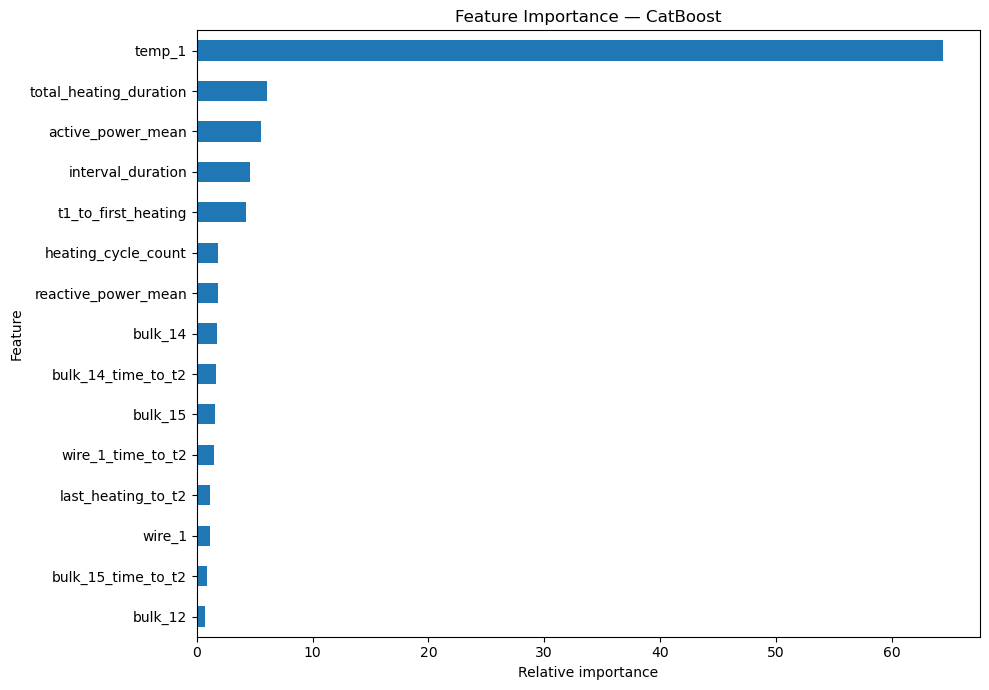

In [100]:
fig, ax = plt.subplots(figsize=(10, 7))

feature_importance.head(15).sort_values().plot(
    kind='barh',
    ax=ax
)

ax.set(
    title='Feature Importance — CatBoost',
    xlabel='Relative importance',
    ylabel='Feature'
)

plt.tight_layout()
plt.show()


When examining relative feature importance, we can see that by far the most important variable is `temp_1`, the temperature at the beginning of the interval. It is reasonable to expect the previous temperature to have high predictive value because it represents the steel's most recently known thermal state. The subsequent temperature will depend on the operations performed during the interval, including heating, material additions, and other processes that can influence its thermal evolution.

This does not mean that the other variables are unimportant, only that they contribute less to our model's predictions. Other variables with substantial importance include `total_heating_duration` (the total heating time during the interval), `active_power_mean` (mean active power across cycles in the interval), `interval_duration` (the interval's total duration), and `t1_to_first_heating` (the time between the first temperature measurement and the start of the first heating cycle). Overall, the most important features tend to be those directly linked to temperature and temperature changes, such as `interval_duration` and `total_heating_duration`.

It is interesting that `active_power_mean` also has relatively high importance compared with other features. This supports the value of obtaining more information about this type of data in a real-world project. It would be useful to know not only the units of `active_power` but also precisely what the column represents—for example, whether it is a sum or the average active power over a heating cycle. Better use of this variable could potentially improve the model.

Some other variables also appear among the 15 most important features, most of them time-related, such as `bulk_15_time_to_t2` and `last_heating_to_t2`. Only a few material quantity features appear in the top 15. In particular, `bulk_14`, `bulk_15`, and `bulk_12` are among the most frequently added materials across batches, as we noted in the planning notebook, in the section "Bulk Material Addition Data (`data_bulk_en`)": "Materials **`bulk_12`**, **`bulk_14`**, and **`bulk_15`** are added in most batches, with addition frequencies of 78%, 90%, and 72%, respectively."

It is important to note that the importance values reported by CatBoost summarize the model's behavior; they do not establish physical relationships among the variables.

## Testing the Best Model on the Test Data

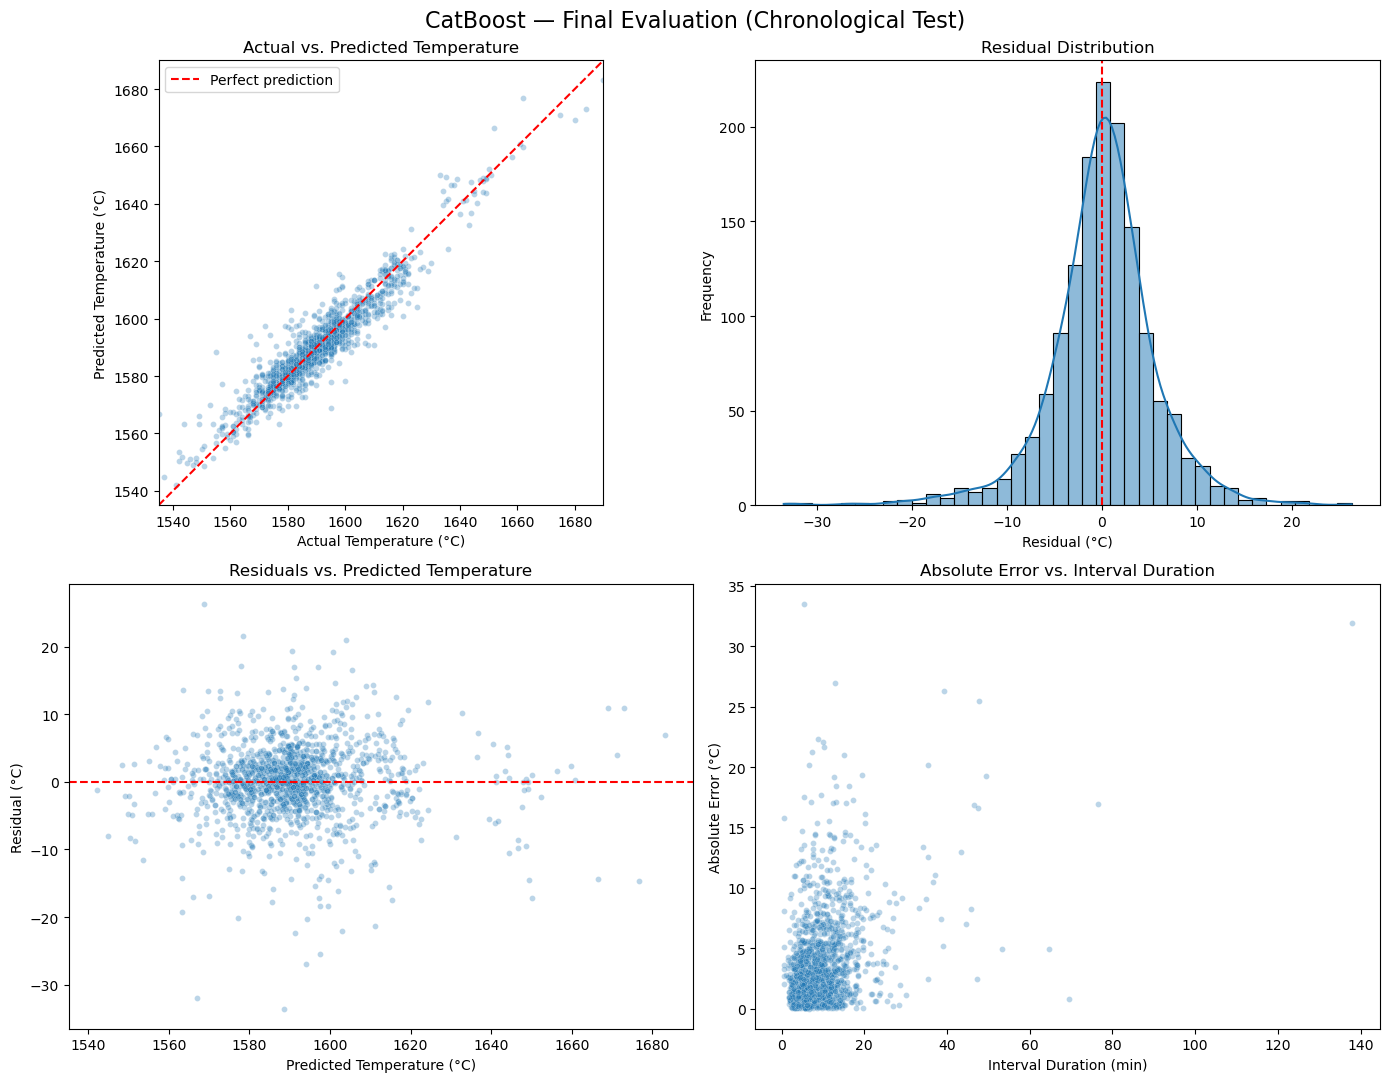

,model,MAE,RMSE,R2,Iem
0,CatBoost,3.928296,5.585677,0.895133,0.592551
1,Persistence,9.641205,13.232861,0.411433,0.000000


In [ ]:
# Predictions on the test set
test_predictions = best_model.predict(features_test)

test_diagnostics = build_diagnostics(
    features_test,
    target_test,
    test_predictions
)

test_diagnostics.to_csv('../../results/test_diagnostics.csv',index=False)

plot_model_diagnostics(
    test_diagnostics,
    'CatBoost — Final Evaluation (Chronological Test)'
)

# Persistence model predictions
persistence_test_predictions = model_persistence.predict(features_test)

# KPIs of the selected model
final_metrics = return_kpi(
    target_test,
    test_predictions,
    persistence_test_predictions
)

persistence_test_metrics = return_kpi(
    target_test,
    persistence_test_predictions,
    persistence_test_predictions
)

final_results = pd.DataFrame([
    {'model': 'CatBoost', **final_metrics},
    {'model': 'Persistence', **persistence_test_metrics}
])



display(final_results)

In [102]:
test_error_by_type = (
    test_diagnostics
    .groupby('interval_type')['absolute_error']
    .agg(
        count='count',
        MAE='mean',
        median_absolute_error='median'
    )
)

display(test_error_by_type)

,count,MAE,median_absolute_error
interval_type,,,
Materials only,67,4.850414,3.623476
With heating,1360,3.882868,2.771131


## Conclusion for the Business Problem

The objective of this project was to develop a regression model capable of predicting steel temperature during secondary refining, functioning as a virtual sensor using information from previous temperature measurements, heating cycles, and material additions.

After processing and selecting the data, we obtained 7,368 temperature measurement intervals for training and testing. The data were split chronologically by batch, preserving independence between the training and test sets as well as the batches' chronological order.

We evaluated Persistence, DummyRegressor, Ridge, RandomForest, LightGBM, and CatBoost. The regression models were compared using cross-validation with GroupKFold, and their hyperparameters were subsequently optimized using RandomizedSearchCV.

**CatBoost was the best-performing model**, achieving an MAE of 4.042°C during cross-validation after hyperparameter optimization. On the test set, the model achieved an MAE of 3.927°C, an RMSE of 5.584°C, and an R² of 0.895, as well as an MAE reduction of approximately 59.25% compared with the Persistence baseline. The performance thresholds were set at 10°C for MAE, 15°C for RMSE, and a 20% reduction in MAE relative to Persistence. All performance thresholds defined for the project were therefore met.

The results show that the operational features used contain relevant information for estimating steel temperature and that the model offers a significant improvement over relying exclusively on the last measured temperature.

However, the residual analysis revealed that some observations still have errors considerably larger than the average. The model also performed worse on intervals without heating but with material additions. These limitations must be considered in any operational application.

Furthermore, the datasets lack complete information about steel chemical composition, gas-purging conditions over time, and product-specific operational tolerances. Therefore, the results of this study alone cannot establish that the model's errors would be acceptable in every production situation.

Another important limitation is that the model was trained on intervals delimited by actual temperature measurements. Consequently, although its use as a virtual sensor is promising, we have not demonstrated that it can estimate temperatures with the same accuracy at arbitrary times during the process. Performance would need to be validated under real operating conditions, using information available up to the prediction timestamp and reference measurements for comparison.

**The model should be considered a candidate tool to support temperature monitoring**, initially subject to validation by Steelproof's process and quality specialists and plant operators. A future implementation should evaluate the model on new batches, establish operational error limits, and specify situations in which direct temperature measurements would remain mandatory. It would also benefit from more information about gas-purging data and electricity use.

The project demonstrated the predictive feasibility of a virtual sensor based on available historical records, but operational adoption would depend on additional validation with production data and company-specific requirements.

As discussed earlier, data limitations prevent a concrete assessment of the model's impact on electricity consumption. However, future model versions combined with more detailed electricity data could yield useful insights into this relationship.

One final possibility would be to reincorporate intervals without heating cycles or material additions, since those observations could help the model learn about passive cooling in batches of steel.

# REFERENCES

- Brown, John — *Foseco Ferrous Foundryman's Handbook*, Butterworth-Heinemann, Woburn, MA, 2000